# Baseline 5: MemAE, shared 100-epoch-cap policy

This is a **2D RGB adaptation of the authors' video MemAE**. It is not a claim to reproduce the original grayscale video experiment. The released memory addressing, shrinkage and entropy mathematics are preserved; only the video convolution backbone was projected to 2D for single waste images. It has 2,511,491 trainable parameters and no external pretraining.

The previous run completed 100 epochs and selected epoch 89. Replaying the new predeclared stopping rule on its recorded normal-validation losses stops at epoch 22 and selects epoch 12. These selected weights are absent from the compact report. Therefore the previous result remains a legacy result, and this notebook creates a separate run. **Do not attach the old 100-epoch checkpoint as `RESUME_DIR`.**

The model learns a memory of normal features. At inference, normal-image memory features reconstruct RGB; residuals become anomaly maps. No real anomaly labels train the network or choose checkpoints or thresholds. No rescue mechanism for all-zero shrunk attention is added: that would alter the method. Attention diagnostics expose this behavior.


## Inputs, policy and outputs

1. Import this `.ipynb` into Kaggle. Attach the same `ws2-eca` dataset used before; enable a GPU. FAIR also needs Internet to obtain hash-verified pinned source files and its dependencies. MemAE embeds the verified authors' source and split manifest.
2. Run all cells. Leave the root overrides blank unless multiple WS2 copies are attached. The embedded manifest enforces the identical 3,829 train / 521 selection / 128 calibration / 234 audit / 496 test frames and video separation. Training and selection use normal images only.
3. Train for **at most 100 epochs**; validate every epoch. Stop after 10 epochs without improvement exceeding `max(1e-8, 0.001 × anchor loss)`. The stopping anchor and the lowest observed loss checkpoint are separate, so tiny improvements can select weights without indefinitely resetting patience. There is no claim that 100 epochs is a journal requirement or that equal epochs equal compute.
4. A nine-hour training guard pauses at a committed epoch boundary. If paused, save the notebook outputs, attach that output dataset to the next session, set `RESUME_DIR` to its extracted directory containing `config.json`, `last.pt`, and `best.pt`, and Run All. Only checkpoints from this same new policy/config/data can resume. A paused run skips calibration and all test evaluation.
5. After the policy finishes, restore the normal-selected checkpoint, lock thresholds before decoding test masks, and evaluate every test frame. Historical IoU is **mean foreground frame IoU** after the same Q3+4×IQR threshold and morphology; it is not background/foreground class mIoU. Also report the independent normal-calibration target FPR=0.02, actual audit FPR, mean frame Dice/precision/recall, pooled metrics, full-pixel AP/AUROC/AUPRO, parameter counts and actual training updates.

Send back the compact `*_100_policy_report.zip` and Kaggle log. Keep `best.pt`, `last.pt`, `final.pt`, and the `*_resume.zip` yourself. Large cached `.npy` files are excluded from the report. `headline_metrics.csv` has the two primary protocols and all pixel ranking metrics in one table. `training_budget.json` records maximum, actual and selected epochs plus optimizer updates. Image AP/AUROC is marked undefined if the test split lacks one image-level class.

The previous notebook and result remain untouched. This notebook cannot guarantee the same test score; changing the stopping policy changes which weights are eligible.


Configuration and safety: the full run, deterministic setup, helpers and stopping policy.

In [1]:
import os, sys, json, time, random, hashlib, shutil, zipfile, base64, zlib
from pathlib import Path
os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG', ':4096:8')
import numpy as np
import pandas as pd
from PIL import Image
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from scipy.ndimage import (gaussian_filter, generate_binary_structure,
    binary_closing, binary_opening, binary_fill_holes, label)
from sklearn.metrics import average_precision_score, roc_auc_score
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from IPython.display import display, FileLink

# Full experiment only. No smoke setting.
INPUT = Path('/kaggle/input')
RUN = Path('/kaggle/working/MemAE_baseline_5_100_policy')
# Normally leave blank. If multiple copies of WS2 are attached, set all four.
TRAIN_ROOT_OVERRIDE = ''
VAL_ROOT_OVERRIDE = ''
TEST_ROOT_OVERRIDE = ''
MASK_ROOT_OVERRIDE = ''
# Optional previous output directory containing config.json, last.pt, best.pt.
RESUME_DIR = ''
SEED = 1337
EPOCHS = 100

PATIENCE = 10
MIN_RELATIVE_IMPROVEMENT = 0.001
MIN_ABSOLUTE_IMPROVEMENT = 1e-8
SESSION_TRAINING_HOURS = 9.0

def advance_stopping(value, anchor, stale):
    value = float(value)
    if not np.isfinite(value):
        raise FloatingPointError('Nonfinite normal-selection loss')
    meaningful = anchor is None or value < anchor - max(
        MIN_ABSOLUTE_IMPROVEMENT, abs(anchor) * MIN_RELATIVE_IMPROVEMENT)
    return (value, 0) if meaningful else (anchor, stale + 1)

def stopping_config():
    return dict(max_epochs=EPOCHS, validation_every=1, patience=PATIENCE,
                min_relative_improvement=MIN_RELATIVE_IMPROVEMENT,
                min_absolute_improvement=MIN_ABSOLUTE_IMPROVEMENT,
                checkpoint='lowest observed normal-selection loss; independent of stopping anchor')

def write_training_metadata():
    write_json(RUN / 'training_budget.json', dict(
        policy=stopping_config(), actual_completed_epochs=completed,
        selected_epoch=best_epoch, selected_normal_loss=float(best),
        optimizer_steps=sum(int(h.get('optimizer_steps', 0)) for h in history),
        sampled_training_images=sum(int(h.get('sampled_frames', 0)) for h in history),
        total_parameters=PARAMETERS,
        trainable_parameters=sum(p.numel() for p in model.parameters() if p.requires_grad),
        frozen_pretrained_parameters=0,
        total_training_seconds=sum(float(h['epoch_seconds']) for h in history),
        stopping_anchor=stop_anchor, stale_epochs=stale_epochs,
        early_stopped=bool(stale_epochs >= PATIENCE),
        complete=bool(TRAINING_COMPLETE), seed=SEED,
        total_epochs_note='100 is a maximum, not a requirement after early stopping',
    ))

BATCH = 10
WORKERS = 2
SIZE = 256
MEMORY_SLOTS = 2000
SHRINK_THRESHOLD = 0.0025
ENTROPY_WEIGHT = 0.0002
LR, WEIGHT_DECAY = 1e-4, 0.0
VALIDATE_EVERY = 1
FPRS = (0.005, 0.01, 0.02, 0.05, 0.10)
SCORES = ('shared_mae', 'squared_error')
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if DEVICE.type != 'cuda':
    raise RuntimeError('Enable a Kaggle GPU before running this full experiment.')
torch.set_num_threads(min(4, os.cpu_count() or 1))
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False

def seed_all(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    torch.cuda.manual_seed_all(s)
seed_all(SEED)

def digest(obj):
    return hashlib.sha256(json.dumps(obj, sort_keys=True).encode()).hexdigest()
def sha(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for b in iter(lambda: f.read(1024*1024), b''): h.update(b)
    return h.hexdigest()
def write_json(path, obj):
    path = Path(path); tmp = path.with_name(path.name+'.tmp')
    tmp.write_text(json.dumps(obj, indent=2, allow_nan=False)); tmp.replace(path)
def save_pt(obj, path):
    path = Path(path); tmp = path.with_name(path.name+'.tmp')
    torch.save(obj, tmp); tmp.replace(path)
def load_pt(path):
    return torch.load(path, map_location=DEVICE, weights_only=True)

def report_zip():
    destination = Path('/kaggle/working/MemAE_baseline_5_100_policy_report.zip')
    with zipfile.ZipFile(destination, 'w', zipfile.ZIP_DEFLATED) as z:
        for p in sorted(RUN.rglob('*')):
            if p.is_file() and '_cache' not in p.relative_to(RUN).parts and p.suffix in {'.json','.csv','.png','.txt','.py'}:
                z.write(p, p.relative_to(RUN))
    return destination
print('Full MemAE-2D RGB experiment:', EPOCHS, 'epochs;', torch.cuda.get_device_name(0))

# Exact record order from qmem_experiment8/20260921_202543_2328f4/splits.json

Full MemAE-2D RGB experiment: 100 epochs; Tesla T4


Data integrity: fixed split records, source provenance, byte hashes and video separation.

In [2]:
REFERENCE = json.loads(zlib.decompress(base64.b64decode('eNqt3c2uLUt2mNd3uW1KPvMnfpKvQhBGSSoaNGhLKJXVEfTuKghuidDOeZSjV8DdGDhAfZErc8WMXP/1j7/+5U///P/+8ff/8F//+Muf/+VPf/3n//LnP/7+jz/901///Jd/81/++T/8+T/+m1+/fv0f//SXP/0/f/4///a/4t/+3//p//rj7/74H//pX//hH//t72ZOIqeQ08hZyNnIOci5yHmME7+Q86nnmK6LGDuJnEJOI2chZyPnIOci5zHOy7qYO596zum6yLGTyCnkNHIWcjZyDnIuch7jvKyLuYN6DtRzoJ4D9Ryo50A9B+o5UM+Bek7Uc6KeE/WcqOdEPSfqOVHPiXpO1HOinutTzzW936ixk8gp5DRyFnI2cg5yLnKeL05PO+yxk8gp5DRyFnI2cg5yLnIe47zc9744a9rzGjuJnEJOI2chZyPnIOci5zHOS89zB/UcqOdAPQfqOVDPgXoO1HOgngP1nKjnRD0n6jlRz4l6TtRzop4T9Zyo50Q9F+q5UM+Fei7Uc6GeC/VcqOdCPRfquVDPjXpu1HOjnhv13KjnRj036rlRz416btTzQj0v1PP61POePp/usZPIKeQ0chZyNnIOci5yHuO8PJ++OGfa8xk7iZxCTiNnIWcj5yDnIucxzkvPcwf1HKjnQD0H6jlQz4F6DtRzoJ4D9Zyo50Q9J+o5Uc+Jek7Uc6KeE/WcqOdEPRfquVDPhXou1HOhnutTz3d6X3fHTiKnkNPIWcjZyDlfnGf6//szdhI5hZxGzkLORs5BzkXOY5yX+/m5g3oO1HOgngP1HKjnQD0H6jlQz4F6TtRzop4T9Zyo50Q9J+o5v/Qc03OI8WvsJHIKOY2chZyNnPPFmZ6zixg7iZxCTiNnIWcj5yDnIucxzs/3Ub/hfOp5es4ucuwkcgo5jZyFnI2cg5yLnMc4L+ti7qCeA/UcqOdAPQfqOVDPgXoO1HOgnhP1nKjnRD0n6jlRz4l6TtRzop4T9Zyo50I9F+q5UM+Fei7Uc6GeC/VcqOdCPRfquVHPjXpu1HN/6nl6HjZq7CRyCjmNnIWcjZyDnIucxzgvzwVz51PP0/O50WMnkVPIaeQs5GzknC/O9BxrrLGTyCnkNHIWcjZyDnIucp4vznRePfbYSeQUcho5CzkbOQc5FzmPcV4+l+cO6jlQz4F6DtRzoJ4D9Ryo50A9B+o5Uc+Jek7Uc6KeE/WcqOdEPSfqOVHPiXou1HOhngv1XKjnQj0X6rlQz4V6LtRzoZ4b9dyfep6es4szdhI5hZxGzkLORs5BzkXO88WZnguIO3YSOYWcRs5CzkbOQc5FzmOcl+fBuYN6DtRzoJ7jU8/T8yDxjJ1ETiGnkbOQs5FzkHOR8xjnZb3PnS8953SuO3+NnUROIaeRs5CzkXOQc5HzGOfndfEbDuo5UM+Beg7Uc6CeA/UcqOdAPcennqfnJjLGTiKnkNPIWcjZyDnIuch5jPNyXZ07n3qenpvIHDuJnEJOI2chZyPnIOci5zHOy7qYO6jnQD0H6jlQz4F6DtRzoJ4D9Ryo50Q9J+o5Uc+Jek7Uc6KeE/WcqOdEPSfquVDPhXou1HOhngv1XKjnQj0X6rlQz4V6btRzf+p5ek4ha+wkcgo5jZyFnI2cg5yLnMc4L/fhcwf1HKjnQD0H6jlQz4F6DtRzoJ4D9Zyo50Q9J+o5Uc+Jek7Uc6KeE/WcqOdEPRfquVDPhXou1HOhngv1XKjnQj3Xp56n5wezx04ip5DTyFnI2cg5yLnIeYzzcr86dz71PD1fmWvsJHIKOY2chZyNnIOci5zHOC/rYu6gngP1HKjnQD0H6jlQz4F6DtRzoJ4T9Zyo50Q9J+o5Uc+Jek7Uc6KeE/WcqOdCPRfquVDPhXou1HOhngv1XKjnQj0X6rlRz416btRzo54b9dyo50Y9N+q5Uc+Nel6o54V6Xp96nr53JffYSeQUcho5CzkbOeeLMz3nm2fsJHIKOY2chZyNnIOci5zHOC/fS7w40/PCecdOIqeQ08hZyNnIOci5yHmM89Lz3PnU8/RcbT5jJ5FTyGnkLORs5JwPTk3PjdavsZPIKeQ0chZyNnIOci5yHuP8fD18c6bn9SrGTiKnkNPIWcjZyDnIuch5jPPS89xBPQfqOVDPgXoO1HOgngP1HKjnQD0n6jlRz4l6TtRzop4T9Zyo50Q9J+o5Uc+Fei7Uc6GeC/VcqOdCPRfquVDPhXou1HOjnhv13KjnRj036rlRz416btRzo54b9bxQzwv1vD71PH1vRuXYSeQUcho5CzkbOeeLMz2nWTV2EjmFnEbOQs5GzkHORc7zxZmev6geO4mcQk4jZyFnI+cg5yLnMc7L92NzB/UcqOdAPcennqfnSmqNnUROIaeRs5CzkXOQc5HzGOdlvc8d1HOgngP1HJ96ns7p1R47iZxCTiNnIWcj5yDnIucxzst6nzufep7OMdYZO4mcQk4jZyFnI+cg5yLnMc7Lupg7n3qezkPWHTuJnEJOI2chZyPnIOci5zHOy7p4caZzjPWMnUROIaeRs5CzkXOQc5HzGOel57mDeg7Uc6CeA/UcX3ru6Rxs/xo7iZxCTiNnIWcj53xxpvOiHWMnkVPIaeQs5GzknC/OdB+2c+wkcgo5jZyFnI2cg5yLnMc4P98nvDnT/eWusZPIKeQ0chZyNnIOcu4XZ7ov3D12EjmFnEbOQs5GzkHORc5jnJfr4Ysz3ffsNXYSOYWcRs5CzkbOQc5FzmOcl55fnOm+Xu+xk8gp5DRyFnI2cg5yLnKeL850H63P2EnkFHIaOQs5GzkHORc5j3FerqtzB/UcqOdAPQfqOVDPgXoO1HOgngP1nJ96nu7n9h07iZxCTiNnIWcj5yDnIucxzsv1ee6gnuNTz9P95X7GTiKnkNPIWcjZyDnIuch5jPOyvn521nTfc/0aO4mcQk4jZyFnI+cg5yLnMc7PPb850/3cFWMnkVPIaeQs5GzkHOTcL850X3jl2EnkFHIaOQs5GzkHORc5j3FerodzB/UcqOf41PN0v3vV2EnkFHIaOQs5GzkHORc5zxdnum++euwkcgo5jZyFnI2cg5z7xZnuU681dhI5hZxGzkLORs5BzkXO88WZ7i+vPXYSOYWcRs5CzkbOQc5FzmOcl/veuYN6DtRzoJ4D9Ryo50A9B+o5UM+Bek7Uc6Ke81PP0zmQdcZOIqeQ08hZyNnIOci5yHmM8/J58eJM983XHTuJnEJOI2chZyPnIOci5zHOS89zB/UcqOdAPQfqOVDPgXoO1HOgngP1nKjnRD0n6jlRz4l6TtRzop4T9Zyo50Q9F+q5UM+Fei7Uc6GeC/VcqOf61PN0fmw9YyeRU8hp5CzkbOScD86ezlntX2MnkVPIaeQs5GzkHORc5DzG+fn54jcc1HOgngP1HKjnQD0H6jlQz4F6DtRzop4T9Zyo50Q9J+o5Uc+Jek7Uc6KeE/VcqOdCPRfquVDPhXou1HOhngv1XKjn+tTzdB57x9hJ5BRyGjkLORs5BzkXOY9xXu575w7qOVDPgXoO1HOgngP1HJ96np4L2Dl2EjmFnEbOQs5GzkHORc7zxZnOve8aO4mcQk4jZyFnI+cg5yLnMc7L5+ncQT0H6jlQz/Gp5+n5gt1jJ5FTyGnkLORs5BzkXOQ8xnlZ7y/O9LzDXmMnkVPIaeQs5GzkHORc5DzGeen5xZmem9h77CRyCjmNnIWcjZyDnIucxzgvPc8d1HN86nk6Z77P2EnkFHIaOQs5GzkHORc5j3Fe1teLM50z33fsJHIKOY2chZyNnPPFmc597WfsJHIKOY2chZyNnIOci5zHOC/XsbnzpecznYs7v8ZOIqeQ08hZyNnIOci5yHm+ONN96hNjJ5FTyGnkLORs5BzkXOQ8X5zpPuPJsZPIKeQ0chZyNnIOci5yHuP8fJ/w5kz3K0+NnUROIaeRs5CzkXOQc5HzGOel57mDeo5PPU/3B0+PnUROIaeRs5CzkXOQc5HzGOdlfc0d1HOgnuNTz9N9z7PGTiKnkNPIWcjZyDnIuch5jPOyTufOp56n+6dnj51ETiGnkbOQs5FzkHOR8xjnZV3MHdRzoJ4D9Ryo50A9B+o5UM+Beg7Uc6KeE/WcqOdEPSfqOVHPiXpO1HOinhP1XKjnQj0X6rlQz4V6LtRzoZ4L9Vyo5/rU83Su6Zyxk8gp5DRyFnI2cg5yLnKeL850HuncsZPIKeQ0chZyNnIOcu4XZzrXdJ6xk8gp5DRyFnI2cg5yLnIe47w8v//s3Ok80v01dhI5hZxGzkLORs5BzkXOY5yfe/4NB/UcqOdAPQfqOVDPgXoO1HOgngP1nKjnRD0n6jlRz4l6TtRzop4T9Zyo50Q9F+q5UM+Fei7Uc6GeC/VcqOdCPRfquVDPjXpu1HOjnhv13KjnRj036rlRz416btTzQj0v1PNCPS/U80I9L9TzQj0v1PNCPa9PPU/Pp9wYO4mcQk4jZyFnI+d8cabnQW6OnUROIaeRs5CzkXOQc5HzfHGm5zhujZ1ETiGnkbOQs5FzkHOR83xxpucdbo+dRE4hp5GzkLORc5BzkfN8cabz/HeNnUROIaeRs5CzkXOQc5HzGOdln2juoJ4D9Ryo50A9B+o5UM+Beg7Uc6CeE/WcqOdEPSfqOVHPiXpO1HN+6nl6nujusZPIKeQ0chZyNnIOci5yni/OdL73nrGTyCnkNHIWcjZyDnIuch7jvNwfzh3Uc6CeA/UcqOdAPQfqOVDPgXoO1HOinhP1nKjnRD0n6jlRz4l6zk89T8873Dt2EjmFnEbOQs5GzkHORc5jnJfP5bmDeg7Uc6CeA/UcqOdAPQfqOVDPgXpO1HOinhP1nKjnRD0n6jlRz4l6TtRzfup5eq7tPmMnkVPIaeQs5GzknA/OMz3/9fwaO4mcQk4jZyFnI+cg5yLn+eJM5/2eGDuJnEJOI2chZyPnIOci5zHOz88pv+GgngP1HKjnQD0H6jk+9TydO31y7CRyCjmNnIWcjZyDnIucxzgv15+5g3oO1HOgngP1HKjnQD0H6jlQz4F6TtRzop4T9Zyo5/zU83Re/amxk8gp5DRyFnI2cg5yLnIe47x8fs0d1HOgngP1HKjnQD0H6jlQz4F6DtRzop4T9Zyo5/zU8/R8ytNjJ5FTyGnkLORs5BzkXOQ8X5zp+ZRnjZ1ETiGnkbOQs5FzkHOR8xjn5f5n7qCeA/UcqOdAPQfqOVDPgXoO1HOgnhP1nKjnRD0n6jlRz4l6zk89T8+VPHvsJHIKOY2chZyNnIOci5zHOC+fp3MH9Ryo50A9B+o5UM+Beg7Uc6CeA/WcqOdEPSfqOVHPiXpO1HOinhP1nKjnRD0X6rlQz4V6LtRzoZ4L9Vyo5/rU8/Tc6HPGTiKnkNPIWcjZyDnIuch5vjjTc1LPHTuJnEJOI2chZyPnIOci5zHOy/PO3PnU8/RcwPOMnUROIaeRs5CzkXOQc//3nfg1PF/wtz8cO4mcQk4jZyFnI+cg5yLnMc6P19XfcVDPgXoO1HOgngP1HJ96jun1J8ZOIqeQ08hZyNnIOci5yHm+ODntMMdOIqeQ08hZyNnIOci5yHmM8/I5OHc+9VzTdVFjJ5FTyGnkLORs5BzkXOQ8xnlZF3PnU889XRc9dhI5hZxGzkLORs5BzkXOY5yXdTF3UM+Beg7Uc6CeA/UcqOdAPQfqOVDPiXpO1HOinhP1nKjnRD0n6jlRz4l6TtRzoZ4L9Vyo50I9F+q5UM+Fei7Uc6GeC/XcqOdGPTfquVHPjXruTz2v6XPKGjuJnEJOI2chZyPnIOci5zHOy3PK3EE9B+o5PvW8p+t0j51ETiGnkbOQs5FzkHOR8xjnZZ3OnU89n+m6OGMnkVPIaeQs5GzkHORc5DzGeVkXcwf1HKjnQD0H6jlQz4F6DtRzfOr5Tq+Hd+wkcgo5jZyFnI2cg5yLnMc4L9fDufOp52e6Lp6xk8gp5DRyFnI2cg5yLnIe47ysi7mDeg7Uc6CeA/UcqOdAPQfqOVDPgXpO1HOinhP1nKjnRD0n6jlRz4l6TtRzop4L9Vyo50I9F+q5UM+Fei7Uc6GeC/VcqOdGPTfquVHPjXpu1HOjnhv13KjnRj036nmhnhfqeaGeF+p5oZ4X6nmhnhfqeaGeF+p5o5436nmjnjfqeaOeN+p5o5436nmjnjfq+aCeD+r5oJ4P6vmgng/q+aCeD+r5oJ4P6vmini/q+aKeL+r5op4v6vminu+XnmP6/oT4NXYSOYWcRs5CzkbOQc5FzvPFmZ6jjxg7iZxCTiNnIWcj5yDnIucxzs/7X7/hoJ7jU8/T9wNEjp1ETiGnkbOQs5FzkHOR8xjnZX3NHdRzoJ4D9Ryo50A9B+o5UM+Beg7Uc6KeE/WcqOdEPSfqOVHPiXpO1HOinhP1XKjnQj0X6rlQz4V6LtRzoZ4L9Vyo5/rU8/T9P1FjJ5FTyGnkLORs5BzkXOQ8X5zp+3aix04ip5DTyFnI2cg5yLnIeYzz8vw1d1DPgXoO1HOgngP1HKjnQD0H6jlQz4l6TtRzop4T9Zyo50Q9J+o5Uc+Jek7Uc6GeC/Vcn3qevscj1thJ5BRyGjkLORs554szfS9E7LGTyCnkNHIWcjZyDnIuch7jvNz3vjjT9znEGTuJnEJOI2chZyPnIOci5/niTM/Rxx07iZxCTiNnIWcj5yDnIucxzst1de6gngP1HKjnQD0H6jk+9Tx9X0E8YyeRU8hp5CzkbOQc5FzkPB+cnM6v5q+xk8gp5DRyFnI2cg5yLnIe4/z8OfgbDuo5UM+Beo5PPU/nhDPGTiKnkNPIWcjZyDnIuch5jPOy3ufOp56n872ZYyeRU8hp5CzkbOQc5FzkPMZ5WRdzB/UcqOdAPQfqOVDP8ann6ZxV1thJ5BRyGjkLORs5BzkXOc8XZzpnlT12EjmFnEbOQs5GzkHORc5jnJfPwbnzqefp/nuusZPIKeQ0chZyNnIOci5yHuO8rIu5g3oO1HOgngP1HKjn+NTzdA4k99hJ5BRyGjkLORs5BzkXOY9xXq4/cwf1HKjnQD0H6jk+9Tydt8kzdhI5hZxGzkLORs5BzkXOY5yX68bcQT0H6jlQz4F6DtRzoJ4D9Ryo50A9J+o5Uc+Jek7Uc6Ke81PP03m/vGMnkVPIaeQs5GzkHORc5DzGefkcfHGm82P5jJ1ETiGnkbOQs5FzkHOR8xjnpee5g3oO1HOgngP1HKjnQD0H6jlQz4F6TtRzop4T9Zyo50Q9J+o5Uc+Jek7Uc6KeC/VcqOdCPRfquVDP9aXnms5j16+xk8gp5DRyFnI2cg5yLnIe4/x8X/cbDuo5UM+Beg7Uc6CeA/UcqOdAPQfqOVHPiXpO1HOinvNTz9PzBRVjJ5FTyGnkLORs5BzkXOQ8xnn5/Jo7n3qeni+oHDuJnEJOI2chZyPnIOci5zHOy7qYO6jn+NTzdH6+auwkcgo5jZyFnI2c88WZzqtXj51ETiGnkbOQs5FzvjjTeexaYyeRU8hp5CzkbOQc5FzkPF+c6Vxu7bGTyCnkNHIWcjZyDnIuch7jvNzXzR3Uc3zqeTq/WmfsJHIKOY2chZyNnIOci5zHOC/ra+6gnuNTz9O5uLpjJ5FTyGnkLORs5BzkXOQ8xnlZX3MH9Ryo50A9B+o5UM+Beg7Uc6CeA/WcqOdEPSfqOVHPiXpO1HOinhP1nKjnRD0X6rlQz4V6LtRzoZ4L9Vyo50I9F+q5UM+Nem7Uc6OeG/XcqOdGPTfquVHPjXpu1PNCPS/U80I9L9TzQj0v1PNCPS/U80I9L9TzRj1v1PNGPW/U80Y9b9TzRj1v1PNGPW/U80E9H9TzQT0f1PP51PP0XGQ9YyeRU8hp5CzkbOQc5FzkPMZ5+T5z7qCeA/UcqOdAPQfqOVDPgXoO1HOgnvNLzz0939S/xk4ip5DTyFnI2cg5yLnIeb4403MKHWMnkVPIaeQs5GzkHORc5DzG+fk+4Tcc1HOgngP1HKjnQD0H6jlQz4F6DtRzop4T9Zyo50Q9J+o5Uc+Jek7Uc6KeE/VcqOdCPRfquVDPhXou1HOhngv1XKjnQj036rlRz416btRzo54b9dyo50Y9N+q5Uc8L9bxQzwv1vFDPC/W8UM8L9bxQzwv1vFDPG/W8Uc8b9bxRz/tTz9Pz+J1jJ5FTyGnkLORs5BzkXOQ8xnn5/ufFmZ5/7xo7iZxCTiNnIWcj5yDnIucxzkvPL870XH/32EnkFHIaOQs5GznnizM9199r7CRyCjmNnIWcjZyDnIucxzgv17G586nn6XsGeo+dRE4hp5GzkLORc5BzkfMY52VdzJ1PPU/fD9Bn7CRyCjmNnIWcjZyDnIucxzgv62LufOp5eq6/79hJ5BRyGjkLORs5Bzn3izOdo+5n7CRyCjmNnIWcjZyDnIucxzgv19WfnTWdO12/xk4ip5DTyFnI2cg5yLlfnOm86Iqxk8gp5DRyFnI2cg5yLnIe4/x8PfwN51PP0320lWMnkVPIaeQs5GzkHORc5DzGeVkXL850H23V2EnkFHIaOQs5GzkHORc5j3Feep47qOf41PN0X2/12EnkFHIaOQs5GzkHOfeLM90fXGvsJHIKOY2chZyNnIOci5zHOC/X57nzqefp/uDaYyeRU8hp5CzkbOQc5NwvznQfbZ2xk8gp5DRyFnI2cg5yLnIe47xcV+cO6jlQz4F6DtRzoJ4D9Ryo50A9B+o5Uc+Jek7Uc37qebpPve7YSeQUcho5CzkbOQc5FznPF2e6372esZPIKeQ0chZyNnIOcu4HZ0/3l/evsZPIKeQ0chZyNnIOci5yni/OdJ96x9hJ5BRyGjkLORs5BzkXOY9xfn6O+w0H9Ryo50A9B+o5UM+Beg7Uc6CeA/WcqOdEPSfqOVHPiXpO1HOinhP1nKjnRD0X6rlQz4V6LtRzoZ4L9Vyo50I916eep/NjO8dOIqeQ08hZyNnIOci5yHm+ONO5r11jJ5FTyGnkLORs5BzkXOQ8xnl5bpo7qOdAPcennqfzY7vHTiKnkNPIWcjZyDnIuch5jPOyTufOp56nc3F7jZ1ETiGnkbOQs5FzkHOR8xjnZV3MHdRzoJ4D9Ryo50A9B+o5UM+Beg7Uc6KeE/WcqOdEPSfqOVHPiXpO1HOinhP1XKjnQj0X6rlQz/Wp5+k89t5jJ5FTyGnkLORs5BzkXOQ8X5zpXPc+YyeRU8hp5CzkbOQc5FzkPF+c6ZznvmMnkVPIaeQs5GzkHORc5DzGeXk+nTuo50A9B+o5UM+Beg7Uc6CeA/UcqOdEPSfqOT/1PJ3H3s/YSeQUcho5CzkbOQc5FzmPcV4+L352znQ+/PwaO4mcQk4jZyFnI+cg5yLn+eJM58NPjJ1ETiGnkbOQs5FzkHOR8xjn5+vqbzifep7OoZ0cO4mcQk4jZyFnI+cg5yLnMc7Lupg7qOdAPQfqOVDPgXoO1HOgnuNTz9N5yFNjJ5FTyGnkLORs5BzkXOQ8xnm5Hr4407nB02MnkVPIaeQs5GzkHORc5DzGeel57qCe41PP0/nDs8ZOIqeQ08hZyNnIOV+c6ZzD2WMnkVPIaeQs5GzkHORc5DzGebmuzh3Uc6Ce41PP0zmQc8ZOIqeQ08hZyNnIOci5yHmM87JOX5zpPMm5YyeRU8hp5CzkbOQc5FzkPMZ56XnufOp5um9+nrGTyCnkNHIWcjZyDnIuch7jvKyLuYN6DtRzoJ4D9Rxfer7T+YT7a+wkcgo5jZyFnI2cg5yLnMc4P183fsNBPQfqOVDPgXoO1HOgngP1HKjnQD3np56nczs3xk4ip5DTyFnI2cg5yLnIeb440zmZm2MnkVPIaeQs5GzkHOTcL850ruDW2EnkFHIaOQs5GznnizPdf789dhI5hZxGzkLORs5BzkXOY5yX54u586nn6b75XWMnkVPIaeQs5GzkHORc5DzGeVkXcwf1HJ96ns4n3D12EjmFnEbOQs5GzkHORc7zxZnuv98zdhI5hZxGzkLORs5BzkXOY5yX6/zcQT0H6jlQz4F6DtRzoJ4D9Ryo50A9J+o5Uc+Jek7Uc6KeE/WcqOdEPSfqOVHP9ann6XzUvWMnkVPIaeQs5GzkHORc5DzGebnfmDuo50A9B+o5UM+Beg7Uc6Ce41PP07m4+4ydRE4hp5GzkLORc5BzkfMY5+V6OHe+9PxM576eX2MnkVPIaeQs5GzkHORc5DzG+Xld/IbzqefpvM0TYyeRU8hp5CzkbOQc5FzkPF+c6bzNk2MnkVPIaeQs5GzkHORc5DzGebk+zx3Uc6CeA/UcqOdAPcennqfzWk+NnUROIaeRs5CzkXO+ONN5rafHTiKnkNPIWcjZyDnIuch5vjjT+ahnjZ1ETiGnkbOQs5FzkHOR83xxpnNEzx47iZxCTiNnIWcj5yDnIucxzst9+NxBPcennqfzUc8ZO4mcQk4jZyFnI+cg5yLnMc7L+po7qOdAPQfqOVDPgXoO1HOgngP1HKjnRD0n6jk/9Tydb3nu2EnkFHIaOQs5GzkHORc5j3FePi/mDuo5UM+Beg7Uc6CeA/UcqOdAPQfqOVHPiXpO1HOinhP1nKjnRD0n6jlRz4l6LtRzfep5Oof2PGMnkVPIaeQs5GzkHORc5DzGeblv+dHJX8P5sb/94dhJ5BRyGjkLORs5BzkXOY9xfuz5dxzUc6CeA/UcqOdAPQfqOVDPgXoO1HOinhP1nKjnRD0n6jlRz4l6TtRzop4T9Vyo50I9F+q5UM+Fei7Uc6GeC/VcqOdCPTfquVHPjXpu1HOjnhv13KjnRj036rlRzwv1vD71HNPnyhg7iZxCTiNnIWcj5yDnIucxzstz5dz51HNO10WOnUROIaeRs5CzkXOQc5HzfHFq2mGNnUROIaeRs5CzkXOQc5HzGOfl+jx3UM+Beg7Uc3zquafrvcdOIqeQ08hZyNnIOci5yHmM87Le586nntd0Xayxk8gp5DRyFnI2cg5yLnIe47ysi7mDeg7Uc3zqeU/X6R47iZxCTiNnIWcj5yDnIuf54pxph2fsJHIKOY2chZyNnIOci5zni3OnHd6xk8gp5DRyFnI2cg5yLnIe47zct8wd1HN86vmZrq9n7CRyCjmNnIWcjZzzwYnpPGT8GjuJnEJOI2chZyPnIOci5zHOz9fVN2e6DxsxdhI5hZxGzkLORs5Bzv3iTPcrI8dOIqeQ08hZyNnIOci5yHmM83I9nDuo50A9B+o5UM+Beg7Uc6CeA/UcqOf81PN0Hz9q7CRyCjmNnIWcjZyDnIucxzgv1+cXZ7pPHT12EjmFnEbOQs5GzkHORc5jnJee5w7qOVDPgXoO1HOgngP1HKjnQD0H6jlRz4l6TtRzop4T9Zyo50Q9J+o5Uc+Jei7Uc6GeC/VcqOdCPRfquVDPhXou1HOhnhv13J96ns7FxRo7iZxCTiNnIWcj5yDnIucxzst9+NxBPQfqOVDPgXoO1HOgngP1HKjnQD0n6jlRz4l6TtRzop4T9Zyo50Q9J+o5Uc+Fei7Uc6Ge61PP07nl2GMnkVPIaeQs5GzkHORc5DxfnOnccpyxk8gp5DRyFnI2cg5yLnKeL850bjnu2EnkFHIaOQs5GzkHORc5j3Fenivnzqeep/PG8YydRE4hp5GzkLORc5BzkfMY52VdzB3Uc6CeA/UcqOdAPQfqOVDPgXoO1HOinhP1nKjnRD0n6jlRz4l6TtRzop4T9Vyo5/rSc07Py+SvsZPIKeQ0chZyNnIOci5yHuP8fN/yGw7qOVDPgXoO1HOgngP1HKjnQD0H6jlRz4l6TtRzop4T9Zyo50Q9J+o5Uc+Jei7Uc6GeC/VcqOdCPRfquT71PD1/mjF2EjmFnEbOQs5GzkHORc5jnJf7w7mDeg7Uc6CeA/UcqOdAPQfqOVDPgXpO1HOinhP1nKjnRD0n6jk/9Tw9j585dhI5hZxGzkLORs5BzkXOY5yXz9O586nn6TnorLGTyCnkNHIWcjZyDnIuch7jvKyLF2d6Djp77CRyCjmNnIWcjZyDnIucxzgvPc8d1HOgngP1HKjnQD0H6jlQz4F6jk89T8+15Ro7iZxCTiNnIWcj5yDnIucxzst19cWZni/IPXYSOYWcRs5CzkbOQc5FzmOcl57nDuo5UM+Beg7Uc6Ce41PP03MlecZOIqeQ08hZyNnIOci5yHm+ONNzJXnHTiKnkNPIWcjZyDnIuch5jPPyOTh3UM+Beg7Uc6CeA/UcqOdAPQfqOVDPiXpO1HOinhP1nKjnRD0n6jlRz/ml55rOEVWMnUROIaeRs5CzkXOQc5HzGOfnz/c3Z7qPXzl2EjmFnEbOQs5GzkHORc7zxZnum1eNnUROIaeRs5CzkXOQc5HzfHGm+93VYyeRU8hp5CzkbOQc5FzkPMZ5+Xx/cab7jLXGTiKnkNPIWcjZyDnIuch5jPPS84sz3WesPXYSOYWcRs5CzkbOQc5FzmOcl57nzqeep/tfdcZOIqeQ08hZyNnIOci5yHmM87Iu5g7qOVDPgXoO1HOgngP1HKjnQD0H6jlRz4l6TtRzop4T9Zyfep7uv9cdO4mcQk4jZyFnI+cg5yLnMc7L5+DcQT0H6jlQz4F6DtRzfOp5+v7MesZOIqeQ08hZyNnIOci5yHmM83L9mTuo50A9B+o5UM+Beg7Uc6CeA/UcqOdEPSfqOVHPiXpO1HOinhP1nKjnRD0n6rlQz4V6LtRzoZ4L9Vyo50I9F+q5UM+Fem7Uc6OeG/XcqOdGPTfquVHPjXpu1HOjnhfqeaGeF+p5oZ4X6nmhnhfqeaGeF+p5oZ436nmjnjfqeX/puafvD+9fYyeRU8hp5CzkbOQc5FzkPMb5+Xub33BQz4F6DtRzoJ4D9Ryo50A9B+o5UM+Jek7Uc6KeE/WcqOdEPeennqfnpDrGTiKnkNPIWcjZyDnIuch5jPPyefo35x//7o///Od/+fO//+sff/8PP5DTker+eZS1pyPVv+EUcho5CzkbOQc5FzmPcV7Snjuo50A9B+o5UM+Beg7Uc6CeA/UcqOdEPSfqOVHPiXpO1HOinhP1nKjnRD0n6rlQz4V6LtRzoZ4L9Vyo50I9F+q5UM+Fem7Uc6OeG/XcqOdGPTfquVHPjXpu1HOjnhfqeaGeF+p5oZ4X6nmhnhfqeaGeF+p5oZ436nmjnjfqeaOeN+p5f+p5emSzz9hJ5BRyGjkLORs5BzkXOY9xXr5Hmjuo50A9B+o5UM+Beg7Uc6CeA/UcqOdEPSfqOVHPiXpO1HOinhP1nKjnRD0n6rlQz4V6LtRzoZ4L9Vyo50I9F+q5UM+Fem7Uc6OeG/XcqOdGPTfquVHPjXpu1HOjnhfqeaGeF+p5oZ4X6nmhnhfqeaGeF+p5oZ436nmjnjfqeaOeN+p5o573p56nr07pO3YSOYWcRs5CzkbOQc5FzvPBWdNXkq8cO4mcQk4jZyFnI+cg5yLnMc7P34u+OdNXSq8eO4mcQk4jZyFnI+cg5yLnMc5Lz3MH9Ryo50A9B+o5UM+Beg7Uc6CeA/WcqOdEPSfqOVHPiXpO1HOinhP1nKjnRD0X6rlQz4V6LtRzoZ4L9Vyo50I9F+q5UM+Nem7Uc6OeG/XcqOdGPTfquVHPjXpu1PNCPS/U80I9L9TzQj0v1PNCPS/U80I9L9TzRj1v1PNGPW/U80Y9b9TzRj1v1PNGPW/U80E9H9TzQT0f1PNBPR/U80E9H9TzQT0f1PNFPV/U80U9X9TzRT1f1PNFPV/U80U93089T3+6be2xk8gp5DRyFnI2cg5yLnKeL850zmHdsZPIKeQ0chZyNnIOci5yHuO87MfNHdRzoJ4D9Ryo50A9B+o5UM+Beg7Uc6KeE/WcqOdEPSfqOVHPiXpO1HOinhP1XKjnQj0X6rlQz4V6LtRzoZ4L9Vyo50I9N+q5Uc+Nem7Uc6OeG/XcqOdGPTfquVHPC/W8UM8L9bxQzwv1vFDPC/W8UM8L9bxQzxv1vFHPG/W8Uc8b9bxRzxv1vFHPG/W8Uc8H9XxQzwf1fFDPB/V8UM8H9XxQzwf1fFDPF/V8Uc8X9XxRzxf1fFHPF/V8Uc8X9XxRzw/q+UE9P6jnB/X8oJ4f1PODen5Qzw/q+TE9x69fyAnkJHIKOY2chZyNnIOcixzUM9ofDLQ/GGh/MND+YKD9wUD7g4H2BwPtDwbaHwy0PxhofzDQ/mCg/cFA+4OB9gcD7Q8G2h8MtD8YaH8w0P5goP3BQPuDgfYH49P+4J7+BNyOsZPIKeQ0chZyNnIOci5yni9OTTussZPIKeQ0chZyNnIOci5yHuP8fD//G86nnqfvpdk9dhI5hZxGzkLORs5BzkXOY5yXdfHiTH9PYZ+xk8gp5DRyFnI2cg5yLnIe47z0PHdQz4F6DtRzoJ4D9Ryo50A9B+o5UM+Jek7Uc6KeE/WcqOdEPSfqOVHPiXpO1HOhngv1XKjnQj0X6rlQz4V6LtRzoZ4L9dyo50Y9N+q5Uc+Nem7Uc6OeG/XcqOdGPa9PPU/P+e47dhI5hZxGzkLORs5BzkXOY5yX58G586nnZ7ounrGTyCnkNHIWcjZyDnIuch7jvKyLufOl5/NruC7Or7GTyCnkNHIWcjZyDnIuch7j/Lwu3pzp/vuJsZPIKeQ0chZyNnIOci5yHuO89Dx3UM+Beg7Uc6CeA/UcqOdAPQfqOVDPiXrOTz1P51tOjZ1ETiGnkbOQs5Fz3px//Ls//v2f/uWf/91f/vTXv0H/8MOvb02f6vrnu+CePtX9hlPIaeQs5GzkHOTcD86aPv2sX2MnkVPIaeQs5GzkHORc5DzGeTn1MndQz4F6DtRzoJ4D9Ryo50A9B+o5UM+Jek7Uc6KeE/WcqOdEPSfqOVHPiXpO1HOhngv1XJ96nn5btmLsJHIKOY2chZyNnIOci5zHOC/3P3MH9Ryo50A9B+o5UM+Beg7Uc6Ce41PP02+nVo2dRE4hp5GzkLORc5BzkfMY5+W6+uKsac9r7CRyCjmNnIWcjZyDnIuc54Ozp9/X7V9jJ5FTyGnkLORs5BzkXOQ8xnmZ4pk7qOdAPQfqOVDPgXoO1HOgngP1HKjnRD0n6jlRz4l6TtRzop4T9Zyo50Q9J+q5UM+Fei7Uc33qeXo/v9fYSeQUcho5CzkbOQc594Nzcjp9k2MnkVPIaeQs5GzkHORc5Dxvzj/+3R9/+v/+wz//9edJoGmR/fO/rKdF/oZTyGnkLORs5BzkXOQ8xvn5yfA3HNRzoJ4D9Ryo50A9B+o5UM+Beg7Uc6KeE/WcqOdEPSfqOVHPiXpO1HOinhP1XKjnQj0X6rlQz4V6LtRzoZ4L9Vyo50I9N+q5Uc+Nem7Uc6OeG/XcqOdGPTfquVHPC/W8UM8L9bxQzwv1vFDPC/W8UM8L9bxQzxv1vFHPG/W8Uc8b9bw/9Tyd3OoaO4mcQk4jZyFnI+cg5yLnMc7L90hz51PP0/dmd4+dRE4hp5GzkLORc5BzkfN8cfa0wz12EjmFnEbOQs5GzkHORc5jnJfr89z50vOavgd+nbGTyCnkNHIWcjZyDnIuch7jvEycz51PPU/fELGesZPIKeQ0chZyNnIOci5yHuO8rIu5g3oO1HOgngP1HKjnQD0H6jlQz4F6TtRzop4T9Zyo50Q9J+o5Uc+Jek7Uc6KeC/VcqOdCPRfquVDPhXou1HOhngv1XKjnRj036rlRz416btRzo54b9dyo50Y9N+p5oZ4X6nmhnhfqeaGeF+p5oZ4X6nmhnhfqeaOeN+p5o5436nmjnjfqeaOeN+p5o5436vmgng/q+aCeD+r5oJ4P6vmgng/q+aCeD+r5op4v6vmini/q+aKeL+r5op4v6vmini/q+UE9P6jnB/X8oJ4f1PODen5Qzw/q+UE9P6bn+PULOV963tPzpzvHTiKnkNPIWcjZyDnIuch5jPPyZqK5g3oO1HOgngP1HKjn+NTzdC5u77GTyCnkNHIWcjZyDnIuch7jvFx/9v94s8Nf//yf/9WLHf7dn//pP/7lz///H/7t3/O/Lvt//sv/+Z/2v5aSScWkZtJi0mbSYdJl0qOkf9X6/77EGg/WeLDGgzUerPFgjQdrPFjjwRpP1niyxpM1nqzxZI0nazxZ48kaT9Z4ssaLNV6s8WKNF2u8WOPFGi/WeLHGizVerPFmjTdrvFnjzRpv1nizxps13qzxZo03a3yxxhdrfLHGF2t8scYXa3yxxhdrfLHGF2t8s8Y3a3yzxjdrfLPGN2t8f2w8xt+JxVxKJhWTmkmLSZtJh0mXSY+S3r4T+w3pY+M5Xi05l5JJxaRm0mLSZtJh0mXSo6S31fIbEms8WOPBGg/WeLDGgzUerPFgjQdrPFnjyRpP1niyxpM1nqzxZI0nazxZ48kaL9Z4scaLNV6s8WKNF2u8WOPFGi/WeLHGmzXerPFmjTdrvFnjzRpv1nizxps13h8br/GTYs2lZFIxqZm0mLSZdJh0mfQo6e1J8Tck1niwxoM1HqzxYI0HazxY48EaD9Z4ssaTNZ6s8WSNJ2s8WePJGk/WeLLGkzVerPFijRdrvFjjxRov1nixxos1XqzxYo03a7xZ480ab9Z4s8abNd4fG+/xs1TPpWRSMamZtJi0mXSYdJn0KOntWepNWuPG11xKJhWTmkmLSZtJh0mXSY+S3hr/DYk1HqzxYI0HazxY48EaD9Z4sMaDNZ6s8WSNJ2s8WePJGk/WeLLGkzWerPFkjRdrvFjjxRov1nixxos1XqzxYo0Xa7xY480ab9Z4s8abNd6s8WaNN2u8WePNGm/W+GKNL9b4Yo0v1vhija+Pje/xU/6eS8mkYlIzaTFpM+kw6TLpUdLbU/5vSKzxYI0HazxY48EaD9Z4sMaDNR6s8WSNJ2s8WePJGk/WeLLGkzWerPFkjSdrvFjjxRov1nixxos1XqzxYo0Xa7w+Nn7G975nLiWTiknNpMWkzaTDpMukR0lv975v0h03fudSMqmY1ExaTNpMOky6THqU9Nb4b0is8WCNB2s8WOPBGg/WeLDGgzUerPFkjSdrPFnjyRpP1niyxpM1nqzxZI0na7xY48UaL9Z4scaLNV6s8WKNF2u8WOPFGm/WeLPGmzXerPFmjTdrvFnjzRpv1nizxhdrfLHGF2t8scYXa3yxxhdrfLHGF2t8scY3a3yzxjdrfLPGN2t8s8Y3a3yzxjdrfLPGD2v8sMYPa/ywxg9r/LDGD2v8sMYPa/ywxi9r/LLGL2v8ssYva/yyxi9r/LLGL2v8ssYf1vjzsfFnvJv0zKVkUjGpmbSYtJl0mHSZ9CjpbTfpNyTWeLDGgzUe3xqP8W8Xxq+5lEwqJjWTFpM2kw6TLpMeJb1cC35H+tj4+FcNIuZSMqmY1ExaTNpMOky6THqU9LZafkNijQdrPFjj8bHx8W82RM6lZFIxqZm0mLSZdJh0mfQo6e1a8BsSazxY48EaD9Z4sMaDNR6s8WCNB2s8WePJGk/WeLLGkzWerPFkjSdrPFnjyRov1nixxos1XqzxYo0Xa7xY48UaL9Z4scabNd6s8WaNN2u8WePNGm/WeLPGmzXerPHFGl+s8cUaX6zxxRpfrPHFGl+s8cUaX6zxzRrfrPHNGt+s8c0a36zxzRrfrPHNGt+s8cMaP6zx87Hx8S8LRc2lZFIxqZm0mLSZdJh0mfS8Sv/43/47eemr3Q==')))
EXPECTED = dict(train=3829, select=521, calibrate=128, audit=234, test=496)
assert {k:len(v) for k,v in REFERENCE.items()} == EXPECTED
EXT = {'.png','.jpg','.jpeg','.bmp','.tif','.tiff'}
def images(root):
    return sorted(p for p in root.rglob('*') if p.is_file() and p.suffix.lower() in EXT)
def unique(paths, name):
    paths = sorted(set(paths))
    if len(paths) != 1:
        raise RuntimeError(f'{name}: expected one location; found {paths}. Set the root overrides.')
    return paths[0]
overrides = [TRAIN_ROOT_OVERRIDE, VAL_ROOT_OVERRIDE, TEST_ROOT_OVERRIDE, MASK_ROOT_OVERRIDE]
if any(overrides):
    if not all(overrides): raise ValueError('Set all four root overrides together.')
    train_root, val_root, test_root, mask_root = map(Path, overrides)
else:
    tv = [p.parent.parent for p in INPUT.rglob('after') if p.is_dir() and p.parent.name=='training' and (p.parent.parent/'validation/after').is_dir()]
    tv = unique([p for p in tv if 'with_background' in str(p).lower()] or tv, 'Training/validation')
    te = unique([p.parent.parent for p in INPUT.rglob('before') if p.is_dir() and p.parent.name=='images' and (p.parent.parent/'masks/before').is_dir()], 'Test')
    train_root, val_root = tv/'training/after', tv/'validation/after'
    test_root, mask_root = te/'images/before', te/'masks/before'
for root in (train_root,val_root,test_root,mask_root):
    if not root.is_dir(): raise FileNotFoundError(root)
for root, roles in [(train_root,['train']), (val_root,['select','calibrate','audit']), (test_root,['test'])]:
    listed = [r['relative'] for role in roles for r in REFERENCE[role]]
    actual = {p.relative_to(root).as_posix() for p in images(root)}
    if len(listed)!=len(set(listed)) or set(listed)!=actual:
        raise RuntimeError(f'Dataset does not match saved split at {root}. Missing: {sorted(set(listed)-actual)[:5]}; extra: {sorted(actual-set(listed))[:5]}')
for a,b in [('select','calibrate'),('select','audit'),('calibrate','audit')]:
    assert not ({r['video'] for r in REFERENCE[a]} & {r['video'] for r in REFERENCE[b]})
roots = dict(train=train_root, select=val_root, calibrate=val_root, audit=val_root, test=test_root)
splits, hashes, owners = {}, {}, {}
for role, records in REFERENCE.items():
    splits[role], hashes[role] = [], []
    for record in tqdm(records, desc='Verify '+role):
        r = dict(record); rel = Path(r['relative'])
        assert not rel.is_absolute() and '..' not in rel.parts and rel.parts[0]==r['video']
        r['path'] = str(roots[role]/rel)
        h = sha(r['path'])
        if h in owners and owners[h]!=role: raise RuntimeError(f'Exact duplicate across {role} and {owners[h]}: {rel}')
        owners[h] = role
        hashes[role].append(dict(relative=r['relative'], sha256=h))
        if role=='test':
            # Read names only here; labels are decoded after thresholds are locked.
            exact = mask_root/rel
            r['mask'] = str(exact if exact.is_file() else unique([p for p in (mask_root/rel.parent).glob(rel.stem+'.*') if p.suffix.lower() in EXT], str(rel)))
        splits[role].append(r)
config = dict(implementation='author_MemAE_2D_RGB_adaptation_v1', seed=SEED, epochs=EPOCHS,
    batch=BATCH, size=SIZE, training_samples="whole 256x256 images", encoder_channels=[96,128,256,256], memory_slots=MEMORY_SLOTS, feature_dim=256, shrink_threshold=SHRINK_THRESHOLD, entropy_weight=ENTROPY_WEIGHT, addressing="official unnormalized dot-product then softmax/shrink/L1 normalize",
    lr=LR, weight_decay=WEIGHT_DECAY, validation_every=VALIDATE_EVERY,
    checkpoint_selection='lowest normal-selection full-image reconstruction MSE', loss='mean RGB reconstruction MSE + 0.0002 * mean attention entropy', author_source_hashes={'models/memory_module.py': '7bd2b54efe6d58af8d43bff291ba793a5c1ba5ba1ba89077f9d997676a5c4e89', 'models/entropy_loss.py': '61e3374ef8d5980f39c964b7e9baba76714f5466ff093ae8466608fb0f1efd26', 'models/memae_3dconv.py': '5146749d8383742c4e2bb7ce6f3eaff1c8798e68ee24c5e1e8754359aabcf642', 'options/training_options.py': '807e6fbbda86c038bd47902bd24a8753e340daef1dfe3c4606b00d298d650044', 'train_video_MemAE.sh': '12f7a55eda5b0307edbe32a0ef0708c98ac9835909006aa1c193be18967288fb', 'LICENSE': 'e79fe616777b98d5e3d21935b53174f31a6d026f550a261ef633b6d7ba2b6c7e'}, repository_commit='ceece7714fb241e82ef3f3785d3d1ed86c28113e',
    initialization='author Conv normal(0,.02), BN normal(1,.02)/zero bias; memory author uniform; conv biases framework defaults', optimizer='Adam, betas=(0.9,0.999), eps=1e-8, foreach=False',
    precision='float32, no AMP or TF32', scheduler='none',
    score_names=list(SCORES), sigma=1, fpr_targets=list(FPRS),
    split_sha256=digest(REFERENCE), data_sha256=digest(hashes),
    historical='all normal-validation pixels, Q3+4*IQR',
    masks='PIL bilinear resize 256, grayscale/255 > 0.5', empty_union_iou=1.0)
config['stopping_policy'] = stopping_config()
if RESUME_DIR and Path(RESUME_DIR).resolve()!=RUN.resolve():
    if RUN.exists() and any(RUN.iterdir()): raise RuntimeError('Output already exists; do not merge runs.')
    RUN.mkdir(parents=True, exist_ok=True)
    for name in ('config.json','last.pt','best.pt'):
        shutil.copy2(Path(RESUME_DIR)/name, RUN/name)
RUN.mkdir(parents=True, exist_ok=True)
if (RUN/'config.json').exists():
    if json.loads((RUN/'config.json').read_text())!=config: raise RuntimeError('Existing output belongs to different settings/data. Use a new RUN directory.')
else:
    if (RUN/'last.pt').exists(): raise RuntimeError('Checkpoint without config.json.')
    write_json(RUN/'config.json',config)
write_json(RUN/'splits.json',splits)
write_json(RUN/'input_hashes.json',hashes)
write_json(RUN/'environment.json',dict(torch=str(torch.__version__),numpy=np.__version__,python=sys.version,gpu=torch.cuda.get_device_name(0)))
CACHE = RUN/'_cache'; CACHE.mkdir(exist_ok=True)
print('Exact split verified:', {k:len(v) for k,v in splits.items()})


AUTHOR_SOURCES = {'models/memory_module.py': "from __future__ import absolute_import, print_function\nimport torch\nfrom torch import nn\nimport math\nfrom torch.nn.parameter import Parameter\nfrom torch.nn import functional as F\nimport numpy as np\n\n#\nclass MemoryUnit(nn.Module):\n    def __init__(self, mem_dim, fea_dim, shrink_thres=0.0025):\n        super(MemoryUnit, self).__init__()\n        self.mem_dim = mem_dim\n        self.fea_dim = fea_dim\n        self.weight = Parameter(torch.Tensor(self.mem_dim, self.fea_dim))  # M x C\n        self.bias = None\n        self.shrink_thres= shrink_thres\n        # self.hard_sparse_shrink_opt = nn.Hardshrink(lambd=shrink_thres)\n\n        self.reset_parameters()\n\n    def reset_parameters(self):\n        stdv = 1. / math.sqrt(self.weight.size(1))\n        self.weight.data.uniform_(-stdv, stdv)\n        if self.bias is not None:\n            self.bias.data.uniform_(-stdv, stdv)\n\n    def forward(self, input):\n        att_weight = F.linear(input, self.weight)  # Fea x Mem^T, (TxC) x (CxM) = TxM\n        att_weight = F.softmax(att_weight, dim=1)  # TxM\n        # ReLU based shrinkage, hard shrinkage for positive value\n        if(self.shrink_thres>0):\n            att_weight = hard_shrink_relu(att_weight, lambd=self.shrink_thres)\n            # att_weight = F.softshrink(att_weight, lambd=self.shrink_thres)\n            # normalize???\n            att_weight = F.normalize(att_weight, p=1, dim=1)\n            # att_weight = F.softmax(att_weight, dim=1)\n            # att_weight = self.hard_sparse_shrink_opt(att_weight)\n        mem_trans = self.weight.permute(1, 0)  # Mem^T, MxC\n        output = F.linear(att_weight, mem_trans)  # AttWeight x Mem^T^T = AW x Mem, (TxM) x (MxC) = TxC\n        return {'output': output, 'att': att_weight}  # output, att_weight\n\n    def extra_repr(self):\n        return 'mem_dim={}, fea_dim={}'.format(\n            self.mem_dim, self.fea_dim is not None\n        )\n\n\n# NxCxHxW -> (NxHxW)xC -> addressing Mem, (NxHxW)xC -> NxCxHxW\nclass MemModule(nn.Module):\n    def __init__(self, mem_dim, fea_dim, shrink_thres=0.0025, device='cuda'):\n        super(MemModule, self).__init__()\n        self.mem_dim = mem_dim\n        self.fea_dim = fea_dim\n        self.shrink_thres = shrink_thres\n        self.memory = MemoryUnit(self.mem_dim, self.fea_dim, self.shrink_thres)\n\n    def forward(self, input):\n        s = input.data.shape\n        l = len(s)\n\n        if l == 3:\n            x = input.permute(0, 2, 1)\n        elif l == 4:\n            x = input.permute(0, 2, 3, 1)\n        elif l == 5:\n            x = input.permute(0, 2, 3, 4, 1)\n        else:\n            x = []\n            print('wrong feature map size')\n        x = x.contiguous()\n        x = x.view(-1, s[1])\n        #\n        y_and = self.memory(x)\n        #\n        y = y_and['output']\n        att = y_and['att']\n\n        if l == 3:\n            y = y.view(s[0], s[2], s[1])\n            y = y.permute(0, 2, 1)\n            att = att.view(s[0], s[2], self.mem_dim)\n            att = att.permute(0, 2, 1)\n        elif l == 4:\n            y = y.view(s[0], s[2], s[3], s[1])\n            y = y.permute(0, 3, 1, 2)\n            att = att.view(s[0], s[2], s[3], self.mem_dim)\n            att = att.permute(0, 3, 1, 2)\n        elif l == 5:\n            y = y.view(s[0], s[2], s[3], s[4], s[1])\n            y = y.permute(0, 4, 1, 2, 3)\n            att = att.view(s[0], s[2], s[3], s[4], self.mem_dim)\n            att = att.permute(0, 4, 1, 2, 3)\n        else:\n            y = x\n            att = att\n            print('wrong feature map size')\n        return {'output': y, 'att': att}\n\n# relu based hard shrinkage function, only works for positive values\ndef hard_shrink_relu(input, lambd=0, epsilon=1e-12):\n    output = (F.relu(input-lambd) * input) / (torch.abs(input - lambd) + epsilon)\n    return output\n\n", 'models/entropy_loss.py': "from __future__ import absolute_import, print_function\nimport torch\nfrom torch import nn\n\n\ndef feature_map_permute(input):\n    s = input.data.shape\n    l = len(s)\n\n    # permute feature channel to the last:\n    # NxCxDxHxW --> NxDxHxW x C\n    if l == 2:\n        x = input # NxC\n    elif l == 3:\n        x = input.permute(0, 2, 1)\n    elif l == 4:\n        x = input.permute(0, 2, 3, 1)\n    elif l == 5:\n        x = input.permute(0, 2, 3, 4, 1)\n    else:\n        x = []\n        print('wrong feature map size')\n    x = x.contiguous()\n    # NxDxHxW x C --> (NxDxHxW) x C\n    x = x.view(-1, s[1])\n    return x\n\nclass EntropyLoss(nn.Module):\n    def __init__(self, eps = 1e-12):\n        super(EntropyLoss, self).__init__()\n        self.eps = eps\n\n    def forward(self, x):\n        b = x * torch.log(x + self.eps)\n        b = -1.0 * b.sum(dim=1)\n        b = b.mean()\n        return b\n\nclass EntropyLossEncap(nn.Module):\n    def __init__(self, eps = 1e-12):\n        super(EntropyLossEncap, self).__init__()\n        self.eps = eps\n        self.entropy_loss = EntropyLoss(eps)\n\n    def forward(self, input):\n        score = feature_map_permute(input)\n        ent_loss_val = self.entropy_loss(score)\n        return ent_loss_val\n\n\n", 'models/memae_3dconv.py': "from __future__ import absolute_import, print_function\nimport torch\nfrom torch import nn\n\nfrom models import MemModule\n\nclass AutoEncoderCov3DMem(nn.Module):\n    def __init__(self, chnum_in, mem_dim, shrink_thres=0.0025):\n        super(AutoEncoderCov3DMem, self).__init__()\n        print('AutoEncoderCov3DMem')\n        self.chnum_in = chnum_in\n        feature_num = 128\n        feature_num_2 = 96\n        feature_num_x2 = 256\n        self.encoder = nn.Sequential(\n            nn.Conv3d(self.chnum_in, feature_num_2, (3, 3, 3), stride=(1, 2, 2), padding=(1, 1, 1)),\n            nn.BatchNorm3d(feature_num_2),\n            nn.LeakyReLU(0.2, inplace=True),\n            nn.Conv3d(feature_num_2, feature_num, (3, 3, 3), stride=(2, 2, 2), padding=(1, 1, 1)),\n            nn.BatchNorm3d(feature_num),\n            nn.LeakyReLU(0.2, inplace=True),\n            nn.Conv3d(feature_num, feature_num_x2, (3, 3, 3), stride=(2, 2, 2), padding=(1, 1, 1)),\n            nn.BatchNorm3d(feature_num_x2),\n            nn.LeakyReLU(0.2, inplace=True),\n            nn.Conv3d(feature_num_x2, feature_num_x2, (3, 3, 3), stride=(2, 2, 2), padding=(1, 1, 1)),\n            nn.BatchNorm3d(feature_num_x2),\n            nn.LeakyReLU(0.2, inplace=True)\n        )\n        self.mem_rep = MemModule(mem_dim=mem_dim, fea_dim=feature_num_x2, shrink_thres =shrink_thres)\n        self.decoder = nn.Sequential(\n            nn.ConvTranspose3d(feature_num_x2, feature_num_x2, (3, 3, 3), stride=(2, 2, 2), padding=(1, 1, 1),\n                               output_padding=(1, 1, 1)),\n            nn.BatchNorm3d(feature_num_x2),\n            nn.LeakyReLU(0.2, inplace=True),\n            nn.ConvTranspose3d(feature_num_x2, feature_num, (3, 3, 3), stride=(2, 2, 2), padding=(1, 1, 1),\n                               output_padding=(1, 1, 1)),\n            nn.BatchNorm3d(feature_num),\n            nn.LeakyReLU(0.2, inplace=True),\n            nn.ConvTranspose3d(feature_num, feature_num_2, (3, 3, 3), stride=(2, 2, 2), padding=(1, 1, 1),\n                               output_padding=(1, 1, 1)),\n            nn.BatchNorm3d(feature_num_2),\n            nn.LeakyReLU(0.2, inplace=True),\n            nn.ConvTranspose3d(feature_num_2, self.chnum_in, (3, 3, 3), stride=(1, 2, 2), padding=(1, 1, 1),\n                               output_padding=(0, 1, 1))\n        )\n\n    def forward(self, x):\n        f = self.encoder(x)\n        res_mem = self.mem_rep(f)\n        f = res_mem['output']\n        att = res_mem['att']\n        output = self.decoder(f)\n        return {'output': output, 'att': att}\n", 'options/training_options.py': 'import argparse\nfrom .testing_options import str2bool\n\n\nclass TrainOptions():\n    def __init__(self):\n        """Reset the class; indicates the class hasn\'t been initailized"""\n        self.initialized = False\n    def initialize(self):\n        parser = argparse.ArgumentParser()\n        parser.add_argument(\'--UseCUDA\', help=\'Use CUDA?\', type=str2bool, nargs=\'?\', default=True)\n        parser.add_argument(\'--NumWorker\', help=\'num of worker for dataloader\', type=int, default=1)\n        parser.add_argument(\'--Mode\', help=\'script mode\', choices=[\'train\', \'eval\'], default=\'train\')\n        parser.add_argument(\'--ModelName\', help=\'AE/MemAE\', type=str, default=\'MemAE\')\n        parser.add_argument(\'--ModelSetting\',\n                            help=\'Conv3D/Conv3DSpar\',\n                            type=str,\n                            default=\'Conv3DSpar\')\n        parser.add_argument(\'--Seed\', type=int, default=1)\n        parser.add_argument(\'--IsDeter\', type=str2bool, help=\'set False for efficiency\', default=True)\n        parser.add_argument(\'--IsTbLog\', type=str2bool, default=True)\n        parser.add_argument(\'--Dataset\', help=\'Dataset\', type=str, default=\'UCSD_P2_256\')\n        parser.add_argument(\'--ImgChnNum\', help=\'image channel\', type=int, default=1)\n        parser.add_argument(\'--FrameNum\', help=\'frame num for video clip\', type=int, default=16)\n        parser.add_argument(\'--BatchSize\', help=\'training batchsize\', type=int, default=14)\n        parser.add_argument(\'--LR\', help=\'learning rate\', type=float, default=1e-4)\n        parser.add_argument(\'--EpochNum\', help=\'max epoch num\', type=int, default=100) \n        parser.add_argument(\'--MemDim\', help=\'Memory Dimention\', type=int, default=2000)\n        parser.add_argument(\'--EntropyLossWeight\', help=\'EntropyLossWeight\', type=float, default=0.0002)\n        parser.add_argument(\'--ShrinkThres\', help=\'ShrinkThres\', type=float, default=0.0025)\n        # ##\n        parser.add_argument(\'--TextLogInterval\', help=\'text log ite interval\', type=int, default=1)\n        parser.add_argument(\'--SnapInterval\', help=\'snap saving ite interval\', type=int, default=100)\n        parser.add_argument(\'--TBImgLogInterval\', help=\'text log ite interval\', type=int, default=200)\n        parser.add_argument(\'--SaveCheckInterval\', help=\'checkpoint saving epoch interval\', type=int, default=1)\n        ##\n        parser.add_argument(\'--DataRoot\', help=\'DataPath\', type=str, default=\'./dataset/\')\n        parser.add_argument(\'--ModelRoot\', help=\'Path for saving model\', type=str, default=\'./models/\')\n        ##\n        parser.add_argument(\'--Suffix\', help=\'Suffix\', type=str, default=\'Non\')\n\n        self.initialized = True\n        self.parser = parser\n        return parser\n\n    def print_options(self, opt):\n        # This function is adapted from \'cycleGAN\' project.\n        message = \'\'\n        message += \'----------------- Options ---------------\\n\'\n        for k, v in sorted(vars(opt).items()):\n            comment = \'\'\n            default = self.parser.get_default(k)\n            if v != default:\n                comment = \'\\t[default: %s]\' % str(default)\n            message += \'{:>25}: {:<30}{}\\n\'.format(str(k), str(v), comment)\n        message += \'----------------- End -------------------\'\n        print(message)\n        self.message = message\n\n    def parse(self, is_print):\n        parser = self.initialize()\n        opt = parser.parse_args()\n        if(is_print):\n            self.print_options(opt)\n        self.opt = opt\n        return self.opt\n\n\n\n', 'train_video_MemAE.sh': 'python script_training.py \\\n    --ModelName MemAE \\\n    --ModelSetting Conv3DSpar \\\n    --Dataset UCSD_P2_256 \\\n    --MemDim 2000 \\\n    --EntropyLossWeight 0.0002 \\\n    --ShrinkThres 0.0025 \\\n    --BatchSize 10 \\\n    --Seed 1 \\\n    --SaveCheckInterval 1 \\\n    --IsTbLog True \\\n    --IsDeter True \\\n    --DataRoot ./datasets/processed/ \\\n    --ModelRoot ./results/ \\\n    --Suffix Non', 'LICENSE': 'MIT License\n\nCopyright (c) 2019 Dong Gong\n\nPermission is hereby granted, free of charge, to any person obtaining a copy\nof this software and associated documentation files (the "Software"), to deal\nin the Software without restriction, including without limitation the rights\nto use, copy, modify, merge, publish, distribute, sublicense, and/or sell\ncopies of the Software, and to permit persons to whom the Software is\nfurnished to do so, subject to the following conditions:\n\nThe above copyright notice and this permission notice shall be included in all\ncopies or substantial portions of the Software.\n\nTHE SOFTWARE IS PROVIDED "AS IS", WITHOUT WARRANTY OF ANY KIND, EXPRESS OR\nIMPLIED, INCLUDING BUT NOT LIMITED TO THE WARRANTIES OF MERCHANTABILITY,\nFITNESS FOR A PARTICULAR PURPOSE AND NONINFRINGEMENT. IN NO EVENT SHALL THE\nAUTHORS OR COPYRIGHT HOLDERS BE LIABLE FOR ANY CLAIM, DAMAGES OR OTHER\nLIABILITY, WHETHER IN AN ACTION OF CONTRACT, TORT OR OTHERWISE, ARISING FROM,\nOUT OF OR IN CONNECTION WITH THE SOFTWARE OR THE USE OR OTHER DEALINGS IN THE\nSOFTWARE.\n'}

source_dir=RUN/'author_sources'; source_dir.mkdir(exist_ok=True)
for name,text in AUTHOR_SOURCES.items():
    target=source_dir/name; target.parent.mkdir(parents=True,exist_ok=True); target.write_text(text)
(RUN/'AUTHOR_LICENSE.txt').write_text(AUTHOR_SOURCES['LICENSE'])

Verify train:   0%|          | 0/3829 [00:00<?, ?it/s]

Verify select:   0%|          | 0/521 [00:00<?, ?it/s]

Verify calibrate:   0%|          | 0/128 [00:00<?, ?it/s]

Verify audit:   0%|          | 0/234 [00:00<?, ?it/s]

Verify test:   0%|          | 0/496 [00:00<?, ?it/s]

Exact split verified: {'train': 3829, 'select': 521, 'calibrate': 128, 'audit': 234, 'test': 496}


1066

Data preparation or network definition: normal RGB inputs and pinned method machinery.

In [3]:
def read_rgb(path):
    with Image.open(path) as im:
        return np.array(im.convert('RGB').resize((SIZE,SIZE),Image.Resampling.BILINEAR),dtype=np.uint8,copy=True)
def cache_images(role):
    path=CACHE/f'images_{role}.npy'; shape=(len(splits[role]),SIZE,SIZE,3)
    if not path.exists():
        temp=CACHE/f'images_{role}.tmp.npy'
        a=np.lib.format.open_memmap(temp,mode='w+',dtype=np.uint8,shape=shape)
        for i,r in enumerate(tqdm(splits[role],desc='Resize '+role)): a[i]=read_rgb(r['path'])
        a.flush(); del a; temp.replace(path)
    a=np.load(path,mmap_mode='r')
    assert a.shape==shape and a.dtype==np.uint8
    return a

class FullImages(Dataset):
    def __init__(self,a): self.a=a
    def __len__(self): return len(self.a)
    def __getitem__(self,i):
        return torch.from_numpy(np.array(self.a[i],copy=True)).permute(2,0,1).float()/255
train_data=FullImages(cache_images('train'))
select_data=FullImages(cache_images('select'))
def batches(data,shuffle=False,epoch=0):
    return DataLoader(data,batch_size=BATCH,shuffle=shuffle,num_workers=WORKERS,pin_memory=True,
                      generator=torch.Generator().manual_seed(SEED+epoch),drop_last=False)
print('Full-frame training images:',len(train_data),'normal-selection images:',len(select_data))

import torch
from torch import nn
import math
from torch.nn.parameter import Parameter
from torch.nn import functional as F
import numpy as np

#

Resize train:   0%|          | 0/3829 [00:00<?, ?it/s]

Resize select:   0%|          | 0/521 [00:00<?, ?it/s]

Full-frame training images: 3829 normal-selection images: 521


Network and objective: preserve the published method while adapting its data interface.

In [4]:
class MemoryUnit(nn.Module):
    def __init__(self, mem_dim, fea_dim, shrink_thres=0.0025):
        super(MemoryUnit, self).__init__()
        self.mem_dim = mem_dim
        self.fea_dim = fea_dim
        self.weight = Parameter(torch.Tensor(self.mem_dim, self.fea_dim))  # M x C
        self.bias = None
        self.shrink_thres= shrink_thres
        # self.hard_sparse_shrink_opt = nn.Hardshrink(lambd=shrink_thres)

        self.reset_parameters()

    def reset_parameters(self):
        stdv = 1. / math.sqrt(self.weight.size(1))
        self.weight.data.uniform_(-stdv, stdv)
        if self.bias is not None:
            self.bias.data.uniform_(-stdv, stdv)

    def forward(self, input):
        att_weight = F.linear(input, self.weight)  # Fea x Mem^T, (TxC) x (CxM) = TxM
        att_weight = F.softmax(att_weight, dim=1)  # TxM
        # ReLU based shrinkage, hard shrinkage for positive value
        if(self.shrink_thres>0):
            att_weight = hard_shrink_relu(att_weight, lambd=self.shrink_thres)
            # att_weight = F.softshrink(att_weight, lambd=self.shrink_thres)
            # normalize???
            att_weight = F.normalize(att_weight, p=1, dim=1)
            # att_weight = F.softmax(att_weight, dim=1)
            # att_weight = self.hard_sparse_shrink_opt(att_weight)
        mem_trans = self.weight.permute(1, 0)  # Mem^T, MxC
        output = F.linear(att_weight, mem_trans)  # AttWeight x Mem^T^T = AW x Mem, (TxM) x (MxC) = TxC
        return {'output': output, 'att': att_weight}  # output, att_weight

    def extra_repr(self):
        return 'mem_dim={}, fea_dim={}'.format(
            self.mem_dim, self.fea_dim is not None
        )


# NxCxHxW -> (NxHxW)xC -> addressing Mem, (NxHxW)xC -> NxCxHxW
class MemModule(nn.Module):
    def __init__(self, mem_dim, fea_dim, shrink_thres=0.0025, device='cuda'):
        super(MemModule, self).__init__()
        self.mem_dim = mem_dim
        self.fea_dim = fea_dim
        self.shrink_thres = shrink_thres
        self.memory = MemoryUnit(self.mem_dim, self.fea_dim, self.shrink_thres)

    def forward(self, input):
        s = input.data.shape
        l = len(s)

        if l == 3:
            x = input.permute(0, 2, 1)
        elif l == 4:
            x = input.permute(0, 2, 3, 1)
        elif l == 5:
            x = input.permute(0, 2, 3, 4, 1)
        else:
            x = []
            print('wrong feature map size')
        x = x.contiguous()
        x = x.view(-1, s[1])
        #
        y_and = self.memory(x)
        #
        y = y_and['output']
        att = y_and['att']

        if l == 3:
            y = y.view(s[0], s[2], s[1])
            y = y.permute(0, 2, 1)
            att = att.view(s[0], s[2], self.mem_dim)
            att = att.permute(0, 2, 1)
        elif l == 4:
            y = y.view(s[0], s[2], s[3], s[1])
            y = y.permute(0, 3, 1, 2)
            att = att.view(s[0], s[2], s[3], self.mem_dim)
            att = att.permute(0, 3, 1, 2)
        elif l == 5:
            y = y.view(s[0], s[2], s[3], s[4], s[1])
            y = y.permute(0, 4, 1, 2, 3)
            att = att.view(s[0], s[2], s[3], s[4], self.mem_dim)
            att = att.permute(0, 4, 1, 2, 3)
        else:
            y = x
            att = att
            print('wrong feature map size')
        return {'output': y, 'att': att}

# relu based hard shrinkage function, only works for positive values
def hard_shrink_relu(input, lambd=0, epsilon=1e-12):
    output = (F.relu(input-lambd) * input) / (torch.abs(input - lambd) + epsilon)
    return output


import torch
from torch import nn


def feature_map_permute(input):
    s = input.data.shape
    l = len(s)

    # permute feature channel to the last:
    # NxCxDxHxW --> NxDxHxW x C
    if l == 2:
        x = input # NxC
    elif l == 3:
        x = input.permute(0, 2, 1)
    elif l == 4:
        x = input.permute(0, 2, 3, 1)
    elif l == 5:
        x = input.permute(0, 2, 3, 4, 1)
    else:
        x = []
        print('wrong feature map size')
    x = x.contiguous()
    # NxDxHxW x C --> (NxDxHxW) x C
    x = x.view(-1, s[1])
    return x

class EntropyLoss(nn.Module):
    def __init__(self, eps = 1e-12):
        super(EntropyLoss, self).__init__()
        self.eps = eps

    def forward(self, x):
        b = x * torch.log(x + self.eps)
        b = -1.0 * b.sum(dim=1)
        b = b.mean()
        return b

class EntropyLossEncap(nn.Module):
    def __init__(self, eps = 1e-12):
        super(EntropyLossEncap, self).__init__()
        self.eps = eps
        self.entropy_loss = EntropyLoss(eps)

    def forward(self, input):
        score = feature_map_permute(input)
        ent_loss_val = self.entropy_loss(score)
        return ent_loss_val



import torch
from torch import nn

Normal-only training: optimizer, validation, atomic recovery and checkpoint selection.

In [5]:
class AutoEncoderCov2DMem(nn.Module):
    def __init__(self, chnum_in, mem_dim, shrink_thres=0.0025):
        super(AutoEncoderCov2DMem, self).__init__()
        print('AutoEncoderCov2DMem')
        self.chnum_in = chnum_in
        feature_num = 128
        feature_num_2 = 96
        feature_num_x2 = 256
        self.encoder = nn.Sequential(
            nn.Conv2d(self.chnum_in, feature_num_2, (3, 3), stride=(2, 2), padding=(1, 1)),
            nn.BatchNorm2d(feature_num_2),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(feature_num_2, feature_num, (3, 3), stride=(2, 2), padding=(1, 1)),
            nn.BatchNorm2d(feature_num),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(feature_num, feature_num_x2, (3, 3), stride=(2, 2), padding=(1, 1)),
            nn.BatchNorm2d(feature_num_x2),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(feature_num_x2, feature_num_x2, (3, 3), stride=(2, 2), padding=(1, 1)),
            nn.BatchNorm2d(feature_num_x2),
            nn.LeakyReLU(0.2, inplace=True)
        )
        self.mem_rep = MemModule(mem_dim=mem_dim, fea_dim=feature_num_x2, shrink_thres =shrink_thres)
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(feature_num_x2, feature_num_x2, (3, 3), stride=(2, 2), padding=(1, 1),
                               output_padding=(1, 1)),
            nn.BatchNorm2d(feature_num_x2),
            nn.LeakyReLU(0.2, inplace=True),
            nn.ConvTranspose2d(feature_num_x2, feature_num, (3, 3), stride=(2, 2), padding=(1, 1),
                               output_padding=(1, 1)),
            nn.BatchNorm2d(feature_num),
            nn.LeakyReLU(0.2, inplace=True),
            nn.ConvTranspose2d(feature_num, feature_num_2, (3, 3), stride=(2, 2), padding=(1, 1),
                               output_padding=(1, 1)),
            nn.BatchNorm2d(feature_num_2),
            nn.LeakyReLU(0.2, inplace=True),
            nn.ConvTranspose2d(feature_num_2, self.chnum_in, (3, 3), stride=(2, 2), padding=(1, 1),
                               output_padding=(1, 1))
        )

    def forward(self, x):
        f = self.encoder(x)
        res_mem = self.mem_rep(f)
        f = res_mem['output']
        att = res_mem['att']
        output = self.decoder(f)
        return {'output': output, 'att': att}

def weights_init(m):
    classname = m.__class__.__name__
    # print(classname)
    if classname.find('Conv') != -1:
        m.weight.data.normal_(0.0, 0.02)
    elif classname.find('BatchNorm') != -1:
        m.weight.data.normal_(1.0, 0.02)
        m.bias.data.fill_(0)


# Separate WS2 harness. The memory and entropy definitions above are unchanged.
@torch.inference_mode()
def reconstruct(model,a):
    x=torch.from_numpy(np.array(a,copy=True)).permute(2,0,1)[None].float().to(DEVICE)/255
    output=model(x)['output']
    result=output[0].permute(1,2,0).cpu().numpy()
    if not np.isfinite(result).all(): raise FloatingPointError('Nonfinite reconstruction')
    return result

def evaluation_snapshot(model):
    return {k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
def assert_evaluation_unchanged(snapshot,model):
    for k,v in model.state_dict().items():
        if not torch.equal(snapshot[k],v.detach().cpu()): raise RuntimeError('Evaluation mutated model state: '+k)

def addressing_metrics(att):
    # Return aggregate counts; zeros are retained as in the author code.
    # No nearest-slot fallback, softmax fallback or temperature is added.
    sums=att.sum(dim=1)
    queries=sums.numel()
    return (int((sums<=1e-12).sum().item()), int((att>0).sum().item()), queries)

seed_all(SEED)
model=AutoEncoderCov2DMem(chnum_in=3,mem_dim=MEMORY_SLOTS,shrink_thres=SHRINK_THRESHOLD).to(DEVICE)
model.apply(weights_init)
entropy_criterion=EntropyLossEncap().to(DEVICE)
PARAMETERS=sum(p.numel() for p in model.parameters())
MEMORY_PARAMETERS=model.mem_rep.memory.weight.numel()
assert PARAMETERS==2511491, PARAMETERS
model.eval(); snapshot=evaluation_snapshot(model)
with torch.no_grad():
    probe=torch.zeros(1,3,SIZE,SIZE,device=DEVICE)
    features=model.encoder(probe); result=model(probe)
    assert features.shape==(1,256,16,16)
    assert result['output'].shape==probe.shape
    assert result['att'].shape==(1,MEMORY_SLOTS,16,16)
    assert bool(torch.isfinite(result['output']).all()) and bool(torch.isfinite(result['att']).all())
    mass=result['att'].sum(1)
    assert bool(((mass<1e-8)|((mass-1).abs()<1e-5)).all())
assert_evaluation_unchanged(snapshot,model)
# Standalone addressing checks do not change the model initialization/RNG.
probe_unit=MemoryUnit(3,2,shrink_thres=.2).to(DEVICE)
with torch.no_grad(): probe_unit.weight.copy_(torch.tensor([[1.,0.],[0.,1.],[-1.,0.]],device=DEVICE))
query=torch.tensor([[2.,.5]],device=DEVICE,requires_grad=True)
res=probe_unit(query)
manual=F.softmax(F.linear(query,probe_unit.weight),dim=1)
manual=F.normalize(hard_shrink_relu(manual,lambd=.2),p=1,dim=1)
torch.testing.assert_close(res['att'],manual)
torch.testing.assert_close(res['output'],manual@probe_unit.weight)
(res['output'].square().mean()+.0002*EntropyLoss()(res['att'])).backward()
assert bool(torch.isfinite(query.grad).all()) and bool(torch.isfinite(probe_unit.weight.grad).all())
with torch.no_grad():
    dense=torch.full((1,3),1/3,device=DEVICE)
    zero=F.normalize(hard_shrink_relu(dense,lambd=.5),p=1,dim=1)
    assert bool((zero==0).all())
    assert abs(float(EntropyLoss()(dense))-np.log(3))<1e-6
    assert float(EntropyLoss()(zero))==0
seed_all(SEED)  # Reset after the standalone check; training reseeds each epoch.
del probe,features,result,mass,snapshot,probe_unit,query,res,manual,dense,zero
(RUN/'architecture.txt').write_text(str(model)+f'\nTotal parameters: {PARAMETERS}\nMemory parameters: {MEMORY_PARAMETERS}\nBackbone parameters: {PARAMETERS-MEMORY_PARAMETERS}\n')
write_json(RUN/'model_provenance.json',dict(repository_commit=config['repository_commit'],author_source_hashes=config['author_source_hashes'],adaptation='3D author backbone spatial projection to RGB Conv2D; memory/entropy definitions unchanged',total_parameters=PARAMETERS,memory_parameters=MEMORY_PARAMETERS))
print('MemAE shape, attention, finite-gradient and evaluation-immutability assertions passed. Parameters:',PARAMETERS)

AutoEncoderCov2DMem
MemAE shape, attention, finite-gradient and evaluation-immutability assertions passed. Parameters: 2511491


Locked evaluation: threshold calibration, residual maps, full metrics and report export.

In [6]:
@torch.inference_mode()
def normal_validation():
    model.eval(); total=0.; count=0; snapshot=evaluation_snapshot(model)
    for x in batches(select_data):
        x=x.to(DEVICE,non_blocking=True); result=model(x); loss=(result['output']-x).square().mean()
        if not bool(torch.isfinite(loss)): raise FloatingPointError('Validation diverged')
        total+=loss.item()*len(x); count+=len(x)
    assert_evaluation_unchanged(snapshot,model)
    return total/count
optimizer=torch.optim.Adam(model.parameters(),lr=LR,weight_decay=WEIGHT_DECAY,betas=(.9,.999),eps=1e-8,foreach=False)
history = []
completed, best, best_epoch = 0, float('inf'), 0
stop_anchor, stale_epochs = None, 0
best_model_cpu = None
if (RUN / 'last.pt').exists():
    state = load_pt(RUN / 'last.pt')
    if state['config_sha256'] != digest(config):
        raise RuntimeError('Checkpoint/config mismatch: only new-policy checkpoints can resume.')
    model.load_state_dict(state['model'])
    optimizer.load_state_dict(state['optimizer'])
    history, completed = state['history'], int(state['epoch'])
    best, best_epoch = float(state['best']), int(state['best_epoch'])
    stop_anchor, stale_epochs = state['stop_anchor'], int(state['stale_epochs'])
    best_model_cpu = state['best_model']
    save_pt(dict(model=best_model_cpu, epoch=best_epoch, select_mse=best,
                 config_sha256=digest(config)), RUN / 'best.pt')
    del state
    print('Resuming after committed epoch', completed, '| selected epoch', best_epoch)

def resume_bundle():
    destination = RUN.parent / 'MemAE_baseline_5_100_policy_resume.zip'
    with zipfile.ZipFile(destination, 'w', zipfile.ZIP_STORED) as z:
        for name in ('config.json', 'last.pt', 'best.pt', 'training_history.csv', 'status.json'):
            p = RUN / name
            if p.exists():
                z.write(p, name)
    return destination

def train_remaining():
    global history, completed, best, best_epoch, stop_anchor, stale_epochs, best_model_cpu
    session_start = time.monotonic()
    try:
        for epoch in range(completed + 1, EPOCHS + 1):
            if stale_epochs >= PATIENCE:
                break
            elapsed = time.monotonic() - session_start
            estimate = max([h['epoch_seconds'] for h in history[-3:]], default=0.)
            if elapsed > 0 and elapsed + estimate > SESSION_TRAINING_HOURS * 3600:
                print('Pausing at a committed epoch boundary before the Kaggle limit.', flush=True)
                break
            begin = time.monotonic()
            seed_all(SEED + epoch)
            model.train()
            total = recon_total = entropy_total = 0.
            count = zero_queries = active_entries = total_queries = steps = 0
            for x in batches(train_data, True, epoch):
                x = x.to(DEVICE, non_blocking=True)
                optimizer.zero_grad(set_to_none=True)
                result = model(x)
                recon_loss = (result['output'] - x).square().mean()
                entropy_loss = entropy_criterion(result['att'])
                loss = recon_loss + ENTROPY_WEIGHT * entropy_loss
                zero, active, queries = addressing_metrics(result['att'].detach())
                zero_queries += zero
                active_entries += active
                total_queries += queries
                if not bool(torch.isfinite(loss)):
                    raise FloatingPointError('Training diverged')
                loss.backward()
                optimizer.step()
                steps += 1
                total += loss.item() * len(x)
                recon_total += recon_loss.item() * len(x)
                entropy_total += entropy_loss.item() * len(x)
                count += len(x)
            assert count == len(train_data)
            val = normal_validation()
            if val < best:
                best, best_epoch = float(val), epoch
                best_model_cpu = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            stop_anchor, stale_epochs = advance_stopping(val, stop_anchor, stale_epochs)
            seconds = time.monotonic() - begin
            history.append(dict(epoch=epoch, train_objective=total/count,
                train_mse=recon_total/count, train_entropy=entropy_total/count,
                zero_query_fraction=zero_queries/total_queries,
                active_slots_per_query=active_entries/total_queries, select_mse=float(val),
                best_epoch=best_epoch, epoch_seconds=seconds, optimizer_steps=steps,
                sampled_frames=count, stopping_anchor=stop_anchor, stale_epochs=stale_epochs))
            completed = epoch
            # last.pt is the atomic commit, including matching best weights and optimizer.
            save_pt(dict(model=model.state_dict(), optimizer=optimizer.state_dict(),
                epoch=completed, best=best, best_epoch=best_epoch, best_model=best_model_cpu,
                history=history, stop_anchor=stop_anchor, stale_epochs=stale_epochs,
                config_sha256=digest(config)), RUN / 'last.pt')
            save_pt(dict(model=best_model_cpu, epoch=best_epoch, select_mse=best,
                         config_sha256=digest(config)), RUN / 'best.pt')
            pd.DataFrame(history).to_csv(RUN / 'training_history.csv', index=False)
            write_json(RUN / 'status.json', dict(status='training', completed_epochs=completed,
                max_epochs=EPOCHS, selected_epoch=best_epoch, stale_epochs=stale_epochs,
                test_evaluated=False))
            print(f'Epoch {epoch}/{EPOCHS}: MSE={recon_total/count:.7f}, '
                  f'select={val:.7f}, best={best_epoch}, stale={stale_epochs}/{PATIENCE}, '
                  f'zero-attention={zero_queries/total_queries:.3%}, {seconds:.1f}s', flush=True)
            if stale_epochs >= PATIENCE:
                print('Normal-only early stopping reached; restore the absolute best checkpoint.')
                break
    except BaseException:
        report_zip()
        if (RUN / 'last.pt').exists():
            resume_bundle()
        raise

train_remaining()
TRAINING_COMPLETE = completed == EPOCHS or stale_epochs >= PATIENCE
write_training_metadata()

Epoch 1/100: MSE=0.0154858, select=0.0052793, best=1, stale=0/10, zero-attention=74.226%, 44.8s
Epoch 2/100: MSE=0.0061560, select=0.0042228, best=2, stale=0/10, zero-attention=67.343%, 46.0s
Epoch 3/100: MSE=0.0052238, select=0.0033125, best=3, stale=0/10, zero-attention=59.057%, 48.0s
Epoch 4/100: MSE=0.0046992, select=0.0032042, best=4, stale=0/10, zero-attention=54.952%, 47.4s
Epoch 5/100: MSE=0.0043073, select=0.0027612, best=5, stale=0/10, zero-attention=51.717%, 47.8s
Epoch 6/100: MSE=0.0040785, select=0.0027106, best=6, stale=0/10, zero-attention=47.522%, 47.7s
Epoch 7/100: MSE=0.0038531, select=0.0026392, best=7, stale=0/10, zero-attention=46.671%, 47.7s
Epoch 8/100: MSE=0.0036064, select=0.0025110, best=8, stale=0/10, zero-attention=46.002%, 47.8s
Epoch 9/100: MSE=0.0034701, select=0.0023025, best=9, stale=0/10, zero-attention=46.563%, 47.8s
Epoch 10/100: MSE=0.0031787, select=0.0022572, best=10, stale=0/10, zero-attention=45.702%, 47.7s
Epoch 11/100: MSE=0.0034017, select=0.

Locked evaluation: threshold calibration, residual maps, full metrics and report export.

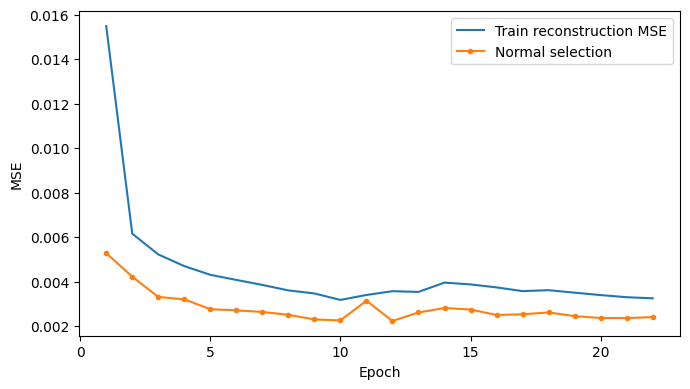

PosixPath('/kaggle/working/MemAE_baseline_5_100_policy_report.zip')

In [7]:
if TRAINING_COMPLETE:
    save_pt(dict(model=model.state_dict(), epoch=completed, config_sha256=digest(config)), RUN / 'final.pt')
    selected = load_pt(RUN / 'best.pt')
    model.load_state_dict(selected['model'])
    model.eval()
    write_json(RUN / 'selected_checkpoint.json', dict(epoch=int(selected['epoch']),
        select_mse=float(selected['select_mse']), sha256=sha(RUN / 'best.pt'),
        trained_epochs=completed, max_epochs=EPOCHS, early_stopped=stale_epochs >= PATIENCE))
    del selected
else:
    write_json(RUN / 'status.json', dict(status='paused_for_resume', completed_epochs=completed,
        max_epochs=EPOCHS, selected_epoch=best_epoch, stale_epochs=stale_epochs,
        test_evaluated=False))
    print('Save this output, attach it to another session, set RESUME_DIR, and Run All.')
    display(FileLink(str(resume_bundle())))
history_df = pd.DataFrame(history)
if len(history_df):
    fig, ax = plt.subplots(figsize=(7,4))
    ax.plot(history_df.epoch, history_df.train_mse, label='Train reconstruction MSE')
    ax.plot(history_df.epoch, history_df.select_mse, 'o-', label='Normal selection', markersize=3)
    ax.set(xlabel='Epoch', ylabel='MSE')
    ax.legend()
    fig.tight_layout()
    fig.savefig(RUN / 'training_curve.png', dpi=150)
    plt.show()
report_zip()

Locked evaluation: threshold calibration, residual maps, full metrics and report export.

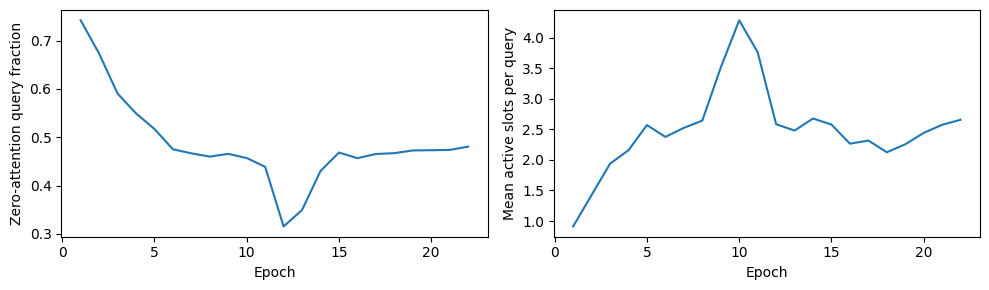

Reconstruct select:   0%|          | 0/521 [00:00<?, ?it/s]

Resize calibrate:   0%|          | 0/128 [00:00<?, ?it/s]

Reconstruct calibrate:   0%|          | 0/128 [00:00<?, ?it/s]

Resize audit:   0%|          | 0/234 [00:00<?, ?it/s]

Reconstruct audit:   0%|          | 0/234 [00:00<?, ?it/s]

...

Full-pixel AP/AUROC: shared_mae
Full-pixel AP/AUROC: squared_error
Historical comparison — use mean_frame_iou, postprocessed:


,score,protocol,processing,model,mean_frame_iou,mean_iou,mean_frame_dice,mean_frame_precision,mean_frame_recall,pooled_dice,...,max_epochs,selected_epoch,n_frames,total_parameters,trainable_parameters,pooled_iou,pooled_precision,pooled_recall,audit_raw_fpr,audit_post_fpr
1,shared_mae,historical,postprocessed,MemAE_2D_RGB_100_policy,0.089929,0.089929,0.161993,0.418203,0.105277,0.161662,...,100,12,496,2511491,2511491,0.087939,0.430071,0.099539,0.022569,0.007128
13,squared_error,historical,postprocessed,MemAE_2D_RGB_100_policy,0.322857,0.322857,0.480284,0.359890,0.776933,0.496114,...,100,12,496,2511491,2511491,0.329888,0.365908,0.770178,0.141215,0.150662


Normal calibration target FPR 0.02:


,score,protocol,processing,model,mean_frame_iou,mean_iou,mean_frame_dice,mean_frame_precision,mean_frame_recall,pooled_dice,...,max_epochs,selected_epoch,n_frames,total_parameters,trainable_parameters,pooled_iou,pooled_precision,pooled_recall,audit_raw_fpr,audit_post_fpr
7,shared_mae,fpr_0.02,postprocessed,MemAE_2D_RGB_100_policy,0.134929,0.134929,0.233446,0.434528,0.167591,0.235810,...,100,12,496,2511491,2511491,0.133665,0.447688,0.160059,0.030306,0.01318
19,squared_error,fpr_0.02,postprocessed,MemAE_2D_RGB_100_policy,0.118248,0.118248,0.207371,0.415260,0.145403,0.208861,...,100,12,496,2511491,2511491,0.116608,0.427620,0.138174,0.030568,0.01229


,score,pixel_ap,pixel_auroc,pixel_aupro_0p30,gt_regions,positive_pixels,negative_pixels
0,shared_mae,0.331438,0.806668,0.505069,3688,4732744,27773112
1,squared_error,0.333156,0.813207,0.509802,3688,4732744,27773112


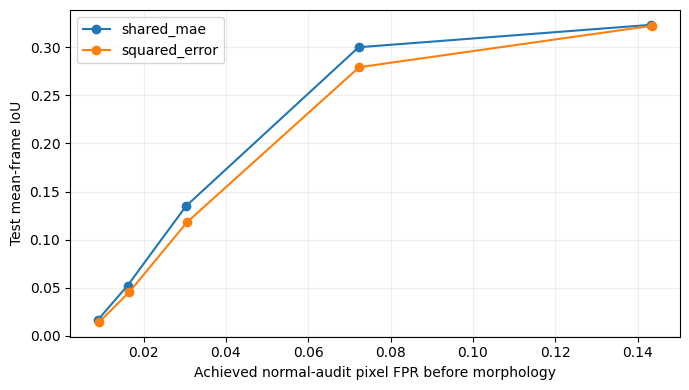

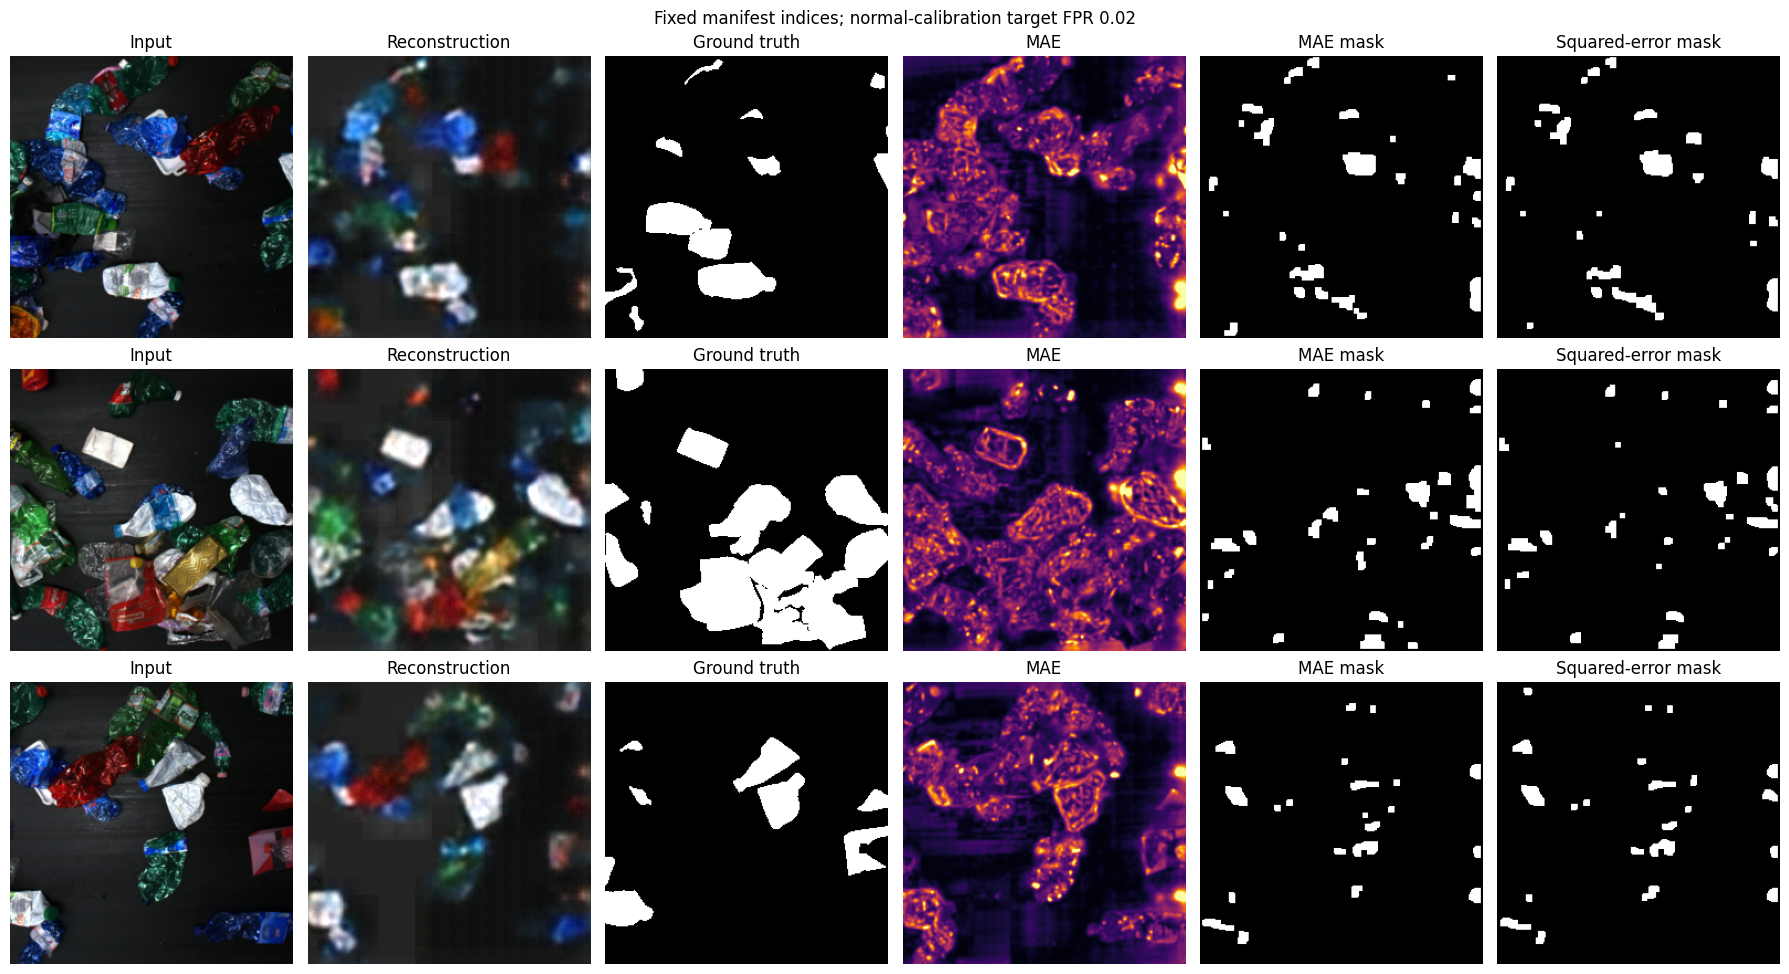

Send back this compact report and the notebook log. No .npy files needed:


/kaggle/working/MemAE_baseline_5_100_policy_report.zip

Retain best.pt, last.pt and final.pt in /kaggle/working/MemAE_baseline_5_100_policy for future inference/resuming.


In [8]:
if TRAINING_COMPLETE:
    fig,axes=plt.subplots(1,2,figsize=(10,3))
    axes[0].plot(history_df.epoch,history_df.zero_query_fraction); axes[0].set(xlabel='Epoch',ylabel='Zero-attention query fraction')
    axes[1].plot(history_df.epoch,history_df.active_slots_per_query); axes[1].set(xlabel='Epoch',ylabel='Mean active slots per query')
    fig.tight_layout(); fig.savefig(RUN/'memory_training_diagnostics.png',dpi=150); plt.show()
    if float(history_df.zero_query_fraction.iloc[-1])>.5:
        print('DIAGNOSTIC: many training queries have zero attention. Retain this run; inspect before drawing a baseline conclusion. No fallback was silently added.')

    STRUCT=generate_binary_structure(2,2)
    def postprocess(mask):
        m=binary_closing(mask,structure=STRUCT,iterations=2)
        m=binary_opening(m,structure=STRUCT,iterations=1); m=binary_fill_holes(m)
        cc,_=label(m); keep=np.bincount(cc.ravel())>=50; keep[0]=False
        return binary_opening(keep[cc],structure=STRUCT,iterations=2)
    MAP_DIR=CACHE/('scores_'+sha(RUN/'best.pt')[:16]); MAP_DIR.mkdir(exist_ok=True)
    def score_maps(role):
        model.eval(); snapshot=evaluation_snapshot(model)
        paths={s:MAP_DIR/f'{s}_{role}.npy' for s in SCORES}
        shape=(len(splits[role]),SIZE,SIZE)
        if not all(p.exists() for p in paths.values()):
            temps={s:p.with_name(p.stem+'.tmp.npy') for s,p in paths.items()}
            arr={s:np.lib.format.open_memmap(p,mode='w+',dtype=np.float32,shape=shape) for s,p in temps.items()}
            data=cache_images(role)
            for i in tqdm(range(len(data)),desc='Reconstruct '+role):
                residual=data[i].astype(np.float32)/255-reconstruct(model,data[i])
                raw={'shared_mae':np.abs(residual).mean(2),'squared_error':np.square(residual).mean(2)}
                for s in SCORES: arr[s][i]=gaussian_filter(raw[s],sigma=1)
            for a in arr.values(): a.flush()
            del a; arr.clear()
            for s in SCORES: temps[s].replace(paths[s])
        result={s:np.load(p,mmap_mode='r') for s,p in paths.items()}
        for a in result.values():
            assert a.shape==shape and a.dtype==np.float32
            for frame in a:
                if not np.isfinite(frame).all(): raise FloatingPointError('Invalid cached scores')
        assert_evaluation_unchanged(snapshot,model)
        return result
    maps={role:score_maps(role) for role in ('select','calibrate','audit')}
    thresholds={}; audit_rows=[]
    for s in SCORES:
        vals=np.concatenate([maps[r][s].ravel() for r in ('select','calibrate','audit')])
        q1,q3=np.percentile(vals,[25,75]); thresholds[s]={'historical':float(q3+4*(q3-q1))}; del vals
        rng=np.random.default_rng(SEED+71)
        sample=np.concatenate([a.ravel()[rng.choice(SIZE*SIZE,4096,replace=False)] for a in maps['calibrate'][s]])
        for f in FPRS: thresholds[s][f'fpr_{f:g}']=float(np.quantile(sample,1-f,method='higher'))
        for protocol,t in thresholds[s].items():
            raw=[]; post=[]
            for a in maps['audit'][s]:
                pred=a>t; raw.append(float(pred.mean())); post.append(float(postprocess(pred).mean()))
            audit_rows.append(dict(score=s,protocol=protocol,threshold=t,audit_raw_fpr=float(np.mean(raw)),audit_post_fpr=float(np.mean(post)),audit_used_in_threshold=(protocol=='historical')))
    write_json(RUN/'thresholds_LOCKED.json',thresholds)
    audit=pd.DataFrame(audit_rows); audit.to_csv(RUN/'normal_fpr.csv',index=False)
    write_json(RUN/'evaluation_lock.json',dict(checkpoint_sha256=sha(RUN/'best.pt'),thresholds_sha256=sha(RUN/'thresholds_LOCKED.json'),config_sha256=digest(config)))
    print('Model and thresholds locked before test masks are decoded.')
    display(audit)

    lock=json.loads((RUN/'evaluation_lock.json').read_text())
    assert lock['checkpoint_sha256']==sha(RUN/'best.pt') and lock['thresholds_sha256']==sha(RUN/'thresholds_LOCKED.json')
    maps['test']=score_maps('test')
    gt=np.lib.format.open_memmap(CACHE/'test_masks.npy',mode='w+',dtype=np.bool_,shape=(len(splits['test']),SIZE,SIZE))
    mask_hashes=[]
    for i,r in enumerate(tqdm(splits['test'],desc='Read locked test masks')):
        with Image.open(r['mask']) as im:
            gt[i]=np.asarray(im.convert('L').resize((SIZE,SIZE),Image.Resampling.BILINEAR),dtype=np.float32)/255>.5
        mask_hashes.append(dict(relative=r['relative'],sha256=sha(r['mask'])))
    gt.flush(); assert gt.any() and not gt.all()
    write_json(RUN/'mask_hashes.json',mask_hashes)
    def confusion(pred,target):
        return (int(np.count_nonzero(pred&target)),int(np.count_nonzero(pred&~target)),int(np.count_nonzero(~pred&target)),int(np.count_nonzero(~pred&~target)))
    def iou(tp,fp,fn): return tp/(tp+fp+fn) if tp+fp+fn else 1.0
    def dice(tp,fp,fn): return 2*tp/(2*tp+fp+fn) if 2*tp+fp+fn else 1.0

    def pixel_ranking(scores, masks):
        # Exact AP/AUROC, with tied scores grouped, using a single sorting pass.
        # PRO gives every 8-connected GT region equal weight, integrates FPR<=0.30,
        # and normalizes by 0.30. Test labels here calculate metrics, not thresholds.
        y = np.asarray(masks, dtype=np.bool_).ravel()
        score = np.asarray(scores, dtype=np.float32).ravel()
        positives, negatives = int(y.sum()), int((~y).sum())
        if positives == 0 or negatives == 0:
            return dict(pixel_ap=None, pixel_auroc=None, pixel_aupro_0p30=None,
                        gt_regions=0, positive_pixels=positives, negative_pixels=negatives)
        weights = np.zeros(masks.shape, dtype=np.float32)
        regions = 0
        for i, m in enumerate(masks):
            cc, n = label(m, structure=STRUCT)
            areas = np.bincount(cc.ravel())
            lookup = np.zeros(len(areas), dtype=np.float32)
            lookup[1:] = 1. / areas[1:]
            weights[i] = lookup[cc]
            regions += n
        order = np.argsort(score, kind='stable')[::-1]
        sorted_scores = score[order]
        ends = np.r_[np.flatnonzero(np.diff(sorted_scores)), len(score) - 1]
        del sorted_scores
        cumsum = np.cumsum(y[order], dtype=np.int64)
        tp = cumsum[ends].astype(np.float64)
        del cumsum
        fp = (ends + 1).astype(np.float64) - tp
        ap = float(np.sum(np.diff(np.r_[0., tp]) * (tp / (ends + 1))) / positives)
        fpr = np.r_[0., fp / negatives]
        tpr = np.r_[0., tp / positives]
        trapz = getattr(np, 'trapezoid', None) or np.trapz
        auroc = float(trapz(tpr, fpr))
        del tp, fp, tpr
        region_cumsum = np.cumsum(weights.ravel()[order], dtype=np.float64)
        pro = np.r_[0., region_cumsum[ends] / regions]
        del region_cumsum, weights, order, ends
        cap = .30
        # Keep all vertical segments at a repeated FPR; interpolate the crossing segment.
        right = int(np.searchsorted(fpr, cap, side='right'))
        xx, yy = fpr[:right], pro[:right]
        if xx[-1] < cap:
            upper = right
            endpoint = yy[-1] + (pro[upper] - yy[-1]) * (cap - xx[-1]) / (fpr[upper] - xx[-1])
            xx = np.r_[xx, cap]
            yy = np.r_[yy, endpoint]
        aupro = float(trapz(yy, xx) / cap)
        return dict(pixel_ap=ap, pixel_auroc=auroc, pixel_aupro_0p30=aupro,
                    gt_regions=int(regions), positive_pixels=positives, negative_pixels=negatives)
    rows=[]
    for s in SCORES:
        for protocol,t in tqdm(thresholds[s].items(),desc='Evaluate '+s):
            for i,r in enumerate(splits['test']):
                raw=maps['test'][s][i]>t
                for processing,pred in [('raw',raw),('postprocessed',postprocess(raw))]:
                    tp,fp,fn,tn=confusion(pred,gt[i])
                    rows.append(dict(score=s,protocol=protocol,processing=processing,relative=r['relative'],video=r['video'],tp=tp,fp=fp,fn=fn,tn=tn,iou=iou(tp,fp,fn),dice=dice(tp,fp,fn),precision=tp/(tp+fp) if tp+fp else 0.,recall=tp/(tp+fn) if tp+fn else 0.))
    frames=pd.DataFrame(rows); frames.to_csv(RUN/'test_frame_metrics.csv',index=False)
    keys=['score','protocol','processing']; summary_rows=[]
    for (s,protocol,processing),group in frames.groupby(keys,sort=False):
        tp,fp,fn,tn=[int(group[c].sum()) for c in ('tp','fp','fn','tn')]
        a=audit[(audit.score==s)&(audit.protocol==protocol)].iloc[0]
        summary_rows.append(dict(score=s,protocol=protocol,processing=processing,model='MemAE_2D_RGB_100_policy',mean_frame_iou=float(group.iou.mean()),mean_iou=float(group.iou.mean()),mean_frame_dice=float(group.dice.mean()),mean_frame_precision=float(group.precision.mean()),mean_frame_recall=float(group.recall.mean()),pooled_dice=dice(tp,fp,fn),actual_epochs=completed,max_epochs=EPOCHS,selected_epoch=best_epoch,n_frames=len(group),total_parameters=PARAMETERS,trainable_parameters=PARAMETERS,pooled_iou=iou(tp,fp,fn),pooled_precision=tp/(tp+fp) if tp+fp else 0.,pooled_recall=tp/(tp+fn) if tp+fn else 0.,audit_raw_fpr=float(a.audit_raw_fpr),audit_post_fpr=float(a.audit_post_fpr)))
    summary=pd.DataFrame(summary_rows); summary.to_csv(RUN/'summary.csv',index=False)
    frames.groupby(keys+['video'],as_index=False).agg(mean_frame_iou=('iou','mean'),frames=('iou','size')).to_csv(RUN/'test_video_metrics.csv',index=False)
    # Exact full-pixel metrics: CPU/RAM intensive, computed sequentially.
    ranking=[]
    for s in SCORES:
        print('Full-pixel AP/AUROC:',s,flush=True)
        ranking.append(dict(score=s,**pixel_ranking(maps['test'][s],gt)))
    pd.DataFrame(ranking).to_csv(RUN/'full_pixel_ranking.csv',index=False)
    print('Historical comparison — use mean_frame_iou, postprocessed:')
    display(summary[(summary.protocol=='historical')&(summary.processing=='postprocessed')])
    print('Normal calibration target FPR 0.02:')
    display(summary[(summary.protocol=='fpr_0.02')&(summary.processing=='postprocessed')])
    display(pd.DataFrame(ranking))

    fig,ax=plt.subplots(figsize=(7,4))
    for s in SCORES:
        d=summary[(summary.score==s)&(summary.processing=='postprocessed')&(summary.protocol!='historical')].sort_values('audit_raw_fpr')
        ax.plot(d.audit_raw_fpr,d.mean_frame_iou,'o-',label=s)
    ax.set(xlabel='Achieved normal-audit pixel FPR before morphology',ylabel='Test mean-frame IoU'); ax.legend(); ax.grid(alpha=.2)
    fig.tight_layout(); fig.savefig(RUN/'iou_vs_fpr.png',dpi=150); plt.show()
    indices=np.linspace(0,len(splits['test'])-1,3,dtype=int); data=cache_images('test')
    fig,axes=plt.subplots(3,6,figsize=(18,10))
    for row,i in enumerate(indices):
        rec=reconstruct(model,data[i]); t=thresholds['shared_mae']['fpr_0.02']; t2=thresholds['squared_error']['fpr_0.02']
        panels=[(data[i],'Input',None),(np.clip(rec,0,1),'Reconstruction',None),(gt[i],'Ground truth','gray'),(maps['test']['shared_mae'][i],'MAE','inferno'),(postprocess(maps['test']['shared_mae'][i]>t),'MAE mask','gray'),(postprocess(maps['test']['squared_error'][i]>t2),'Squared-error mask','gray')]
        for col,(a,title,cmap) in enumerate(panels):
            if col==3: axes[row,col].imshow(a,cmap=cmap,vmin=0,vmax=max(2*t,1e-8))
            else: axes[row,col].imshow(a,cmap=cmap)
            axes[row,col].set_title(title); axes[row,col].axis('off')
    fig.suptitle('Fixed manifest indices; normal-calibration target FPR 0.02')
    fig.tight_layout(); fig.savefig(RUN/'fixed_examples.png',dpi=150); plt.show()
    write_json(RUN/'fixed_examples.json',[splits['test'][int(i)]['relative'] for i in indices])
    write_training_metadata()
    write_json(RUN/'status.json',dict(status='complete',completed_epochs=completed,max_epochs=EPOCHS,parameters=PARAMETERS,selected_epoch=best_epoch,early_stopped=stale_epochs>=PATIENCE,test_evaluated=True))
    image_rows=[]
    image_y=np.any(gt,axis=(1,2))
    for s in SCORES:
        image_score=np.max(maps['test'][s],axis=(1,2))
        has_both=bool(image_y.any() and (~image_y).any())
        image_rows.append(dict(score=s,image_ap=float(average_precision_score(image_y,image_score)) if has_both else None,image_auroc=float(roc_auc_score(image_y,image_score)) if has_both else None,n_normal_images=int((~image_y).sum()),n_anomalous_images=int(image_y.sum()),image_score='maximum native map value',undefined_reason=None if has_both else 'Test split does not contain both normal and anomalous images'))
    write_json(RUN/'image_ranking.json',image_rows)
    headline=summary[(summary.processing=='postprocessed') & summary.protocol.isin(['historical','fpr_0.02'])].merge(pd.DataFrame(ranking),on='score')
    headline.to_csv(RUN/'headline_metrics.csv',index=False)
    # Save executed cell history for reproducibility, without notebook outputs.
    (RUN/'executed_cells.py').write_text('\n\n'.join(get_ipython().history_manager.input_hist_raw))
    report=report_zip()
    print('Send back this compact report and the notebook log. No .npy files needed:')
    display(FileLink(str(report)))
    print('Retain best.pt, last.pt and final.pt in',RUN,'for future inference/resuming.')
else:
    print("Calibration and test evaluation skipped until training policy is complete.")